# Mapping county health need and care indicators

This notebook is descriptive, not predictive. The first axis is the PLACES-based `NeedScore`. For a cautious quality-related comparison, the second axis is a **readmission-based effectiveness proxy**: counties with lower CMS-reported acute readmission rates score higher. Readmissions are only one imperfect indicator, not a complete measure of effectiveness.

ER visits and Medicare spending are shown separately as utilization/resource-use context. Low ER use or spending is not automatically better, and this analysis does not measure healthcare efficiency or establish causes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
county_need = pd.read_csv(PROJECT_ROOT / "data/processed/county_need_2024.csv")
cms24 = pd.read_csv(PROJECT_ROOT / "data/processed/cms24_county_small.csv")

In [2]:
county_need["CountyFIPS"] = (
    county_need["CountyFIPS"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)
cms24["BENE_GEO_CD"] = (
    cms24["BENE_GEO_CD"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

analysis_df = county_need.merge(
    cms24,
    left_on="CountyFIPS",
    right_on="BENE_GEO_CD",
    how="inner",
    validate="one_to_one",
)

metric_columns = [
    "NeedScore",
    "ER_VISITS_PER_1000_BENES",
    "ACUTE_HOSP_READMSN_PCT",
    "TOT_MDCR_STDZD_PYMT_PC",
    "BENES_TOTAL_CNT",
    "FQHC_RHC_VISITS_PER_1000_BENES",
    "OP_VISITS_PER_1000_BENES",
    "MA_PRTCPTN_RATE",
    "BENE_DUAL_PCT",
]
for column in metric_columns:
    analysis_df[column] = pd.to_numeric(
        analysis_df[column].astype(str).str.replace(",", "", regex=False),
        errors="coerce",
    )

print(f"Merged counties: {len(analysis_df):,}")

Merged counties: 3,142


## Prepare the primary comparison and sensitivity scores

The primary vertical axis will use the readmission measure alone, reversed and standardized. This avoids combining care quality, utilization, and cost into one label. We will also compare that priority group with two alternate summaries: a mean of readmission/ER indicators, and a three-indicator score that additionally treats lower spending as favorable. These alternatives are sensitivity checks, not validated efficiency scores. Using complete cases for all components makes the comparisons use the same counties.

In [3]:
care_indicators = [
    "ER_VISITS_PER_1000_BENES",
    "ACUTE_HOSP_READMSN_PCT",
    "TOT_MDCR_STDZD_PYMT_PC",
]
score_df = analysis_df[
    [
        "StateAbbr", "CountyName", "CountyFIPS", "total_population",
        "NeedScore", "BENES_TOTAL_CNT", "FQHC_RHC_VISITS_PER_1000_BENES",
        "OP_VISITS_PER_1000_BENES", "MA_PRTCPTN_RATE", "BENE_DUAL_PCT",
    ]
    + care_indicators
].dropna(subset=["NeedScore", *care_indicators]).copy()

for column in care_indicators:
    score_df[f"{column}_z"] = (
        score_df[column] - score_df[column].mean()
    ) / score_df[column].std()

score_df["ReadmissionEffectivenessProxy"] = -score_df["ACUTE_HOSP_READMSN_PCT_z"]
score_df["ReadmissionErSummary"] = -score_df[
    ["ACUTE_HOSP_READMSN_PCT_z", "ER_VISITS_PER_1000_BENES_z"]
].mean(axis=1)
score_df["ThreeIndicatorSummary"] = -score_df[
    [f"{column}_z" for column in care_indicators]
].mean(axis=1)

score_df[[
    "NeedScore", "ReadmissionEffectivenessProxy",
    "ReadmissionErSummary", "ThreeIndicatorSummary",
]].describe().T

,count,mean,std,min,25%,50%,75%,max
NeedScore,2996.0,1.360233e+00,2.065968,-4.492298,-0.075007,1.162341,2.866045,9.314433
ReadmissionEffectivenessProxy,2996.0,7.328361e-16,1.000000,-6.968722,-0.608394,-0.015593,0.613235,5.555426
ReadmissionErSummary,2996.0,6.640586e-17,0.817728,-4.961072,-0.512760,0.013324,0.490646,4.753985
ThreeIndicatorSummary,2996.0,1.849878e-16,0.747930,-4.610358,-0.441991,0.019198,0.472570,4.344204


## Visualize need versus the readmission proxy

The quadrant with above-median need and a below-median readmission proxy contains counties with higher need and higher readmission rates. Call these **priority candidates for investigation**, not proven underperformers. A high readmission rate can have multiple causes.

In [4]:
need_cutoff = score_df["NeedScore"].median()
performance_cutoff = score_df["ReadmissionEffectivenessProxy"].median()

def assign_quadrant(row):
    high_need = row["NeedScore"] >= need_cutoff
    higher_readmission_proxy = row["ReadmissionEffectivenessProxy"] >= performance_cutoff
    if high_need and not higher_readmission_proxy:
        return "High need / higher readmissions"
    if high_need and higher_readmission_proxy:
        return "High need / lower readmissions"
    if not high_need and higher_readmission_proxy:
        return "Lower need / lower readmissions"
    return "Lower need / higher readmissions"

score_df["Quadrant"] = score_df.apply(assign_quadrant, axis=1)
score_df["Priority"] = score_df["Quadrant"].eq("High need / higher readmissions")
score_df["Quadrant"].value_counts().to_frame("count")

,count
Quadrant,
Lower need / lower readmissions,849
High need / higher readmissions,848
High need / lower readmissions,650
Lower need / higher readmissions,649


## Test stricter priority cutoffs

Median splits flag about half the counties on each axis. As a sensitivity check, define a stricter group using the top quartile of NeedScore and the top quartile of the observed readmission rate. It will usually be a subset of the median-based priority group; report the overlap and any exceptions rather than assuming that. Quantile ties can make group sizes slightly larger than exactly 25%.

In [5]:
need_q75 = score_df["NeedScore"].quantile(0.75)
readmission_q75 = score_df["ACUTE_HOSP_READMSN_PCT"].quantile(0.75)
score_df["StrictPriority"] = (
    score_df["NeedScore"].ge(need_q75)
    & score_df["ACUTE_HOSP_READMSN_PCT"].ge(readmission_q75)
)

strict_count = int(score_df["StrictPriority"].sum())
median_priority_count = int(score_df["Priority"].sum())
strict_outside_median = int(
    (score_df["StrictPriority"] & ~score_df["Priority"]).sum()
)
threshold_summary = pd.Series({
    "NeedScore 75th-percentile cutoff": need_q75,
    "Readmission-rate 75th-percentile cutoff": readmission_q75,
    "Median-based priority counties": median_priority_count,
    "Top-quartile priority counties": strict_count,
    "Median-priority group retained (%)": round(
        100 * strict_count / median_priority_count, 1
    ),
    "Strict counties outside median priority": strict_outside_median,
})
threshold_summary

NeedScore 75th-percentile cutoff             2.866045
Readmission-rate 75th-percentile cutoff      0.188200
Median-based priority counties             848.000000
Top-quartile priority counties             289.000000
Median-priority group retained (%)          34.100000
Strict counties outside median priority      0.000000
dtype: float64

In [6]:
strict_priority_counties = (
    score_df[score_df["StrictPriority"]]
    .sort_values(
        ["NeedScore", "ACUTE_HOSP_READMSN_PCT"],
        ascending=[False, False],
    )
    [[
        "StateAbbr", "CountyName", "CountyFIPS", "BENES_TOTAL_CNT",
        "NeedScore", "ACUTE_HOSP_READMSN_PCT",
    ]]
)
strict_priority_counties.head(20)

,StateAbbr,CountyName,CountyFIPS,BENES_TOTAL_CNT,NeedScore,ACUTE_HOSP_READMSN_PCT
2413,SD,Oglala Lakota,46102,1458.0,7.440376,0.2380
3093,WV,Mingo,54059,6843.0,7.257157,0.2750
2587,TX,Dimmit,48127,1983.0,7.117166,0.2471
1067,KY,Magoffin,21153,3366.0,7.080552,0.1988
1543,MS,Humphreys,28053,2034.0,7.050507,0.2273
150,AR,Phillips,05107,4320.0,7.017548,0.2014
1146,LA,Madison,22065,2102.0,6.841615,0.1899
1058,KY,Lee,21129,1841.0,6.698802,0.3025
2422,SD,Todd,46121,1019.0,6.685771,0.2261
507,GA,Randolph,13243,1741.0,6.612370,0.2600


## Check whether priority counties depend on the score definition

Use the same complete-case counties and the same median need cutoff for each version. The readmission-only proxy is the primary definition. The other versions add ER visits and then spending; comparing their overlap shows how sensitive the flagged group is to assumptions about what counts as better care.

In [7]:
score_definitions = {
    "Readmissions only (primary)": "ReadmissionEffectivenessProxy",
    "Readmissions + ER visits": "ReadmissionErSummary",
    "Readmissions + ER + spending": "ThreeIndicatorSummary",
}
primary_priority = score_df["Priority"]
sensitivity_rows = []

for label, column in score_definitions.items():
    is_priority = (
        score_df["NeedScore"].ge(need_cutoff)
        & score_df[column].lt(score_df[column].median())
    )
    intersection = (is_priority & primary_priority).sum()
    union = (is_priority | primary_priority).sum()
    sensitivity_rows.append({
        "Score definition": label,
        "Priority counties": int(is_priority.sum()),
        "Same as primary": int(intersection),
        "Overlap with primary (%)": round(100 * intersection / primary_priority.sum(), 1),
        "Jaccard similarity": round(intersection / union, 3) if union else 1.0,
    })

sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table

,Score definition,Priority counties,Same as primary,Overlap with primary (%),Jaccard similarity
0,Readmissions only (primary),848,848,100.0,1.000
1,Readmissions + ER visits,947,763,90.0,0.739
2,Readmissions + ER + spending,970,732,86.3,0.674


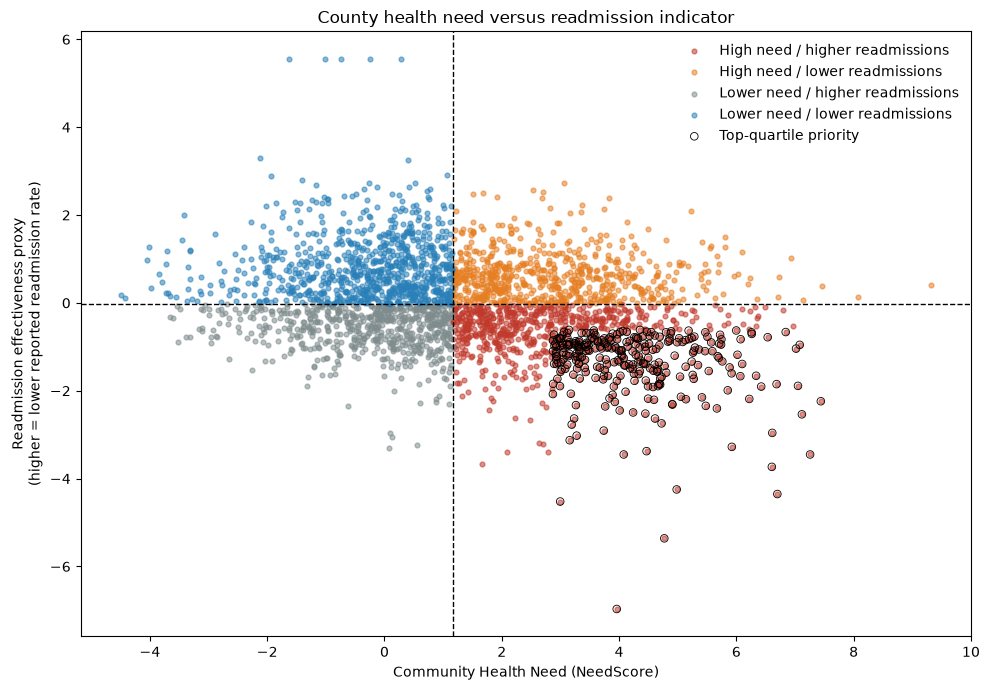

In [8]:
colors = {
    "High need / higher readmissions": "#c0392b",
    "High need / lower readmissions": "#e67e22",
    "Lower need / lower readmissions": "#2980b9",
    "Lower need / higher readmissions": "#7f8c8d",
}

fig, ax = plt.subplots(figsize=(10, 7))
for quadrant, group in score_df.groupby("Quadrant"):
    ax.scatter(
        group["NeedScore"],
        group["ReadmissionEffectivenessProxy"],
        s=12,
        alpha=0.55,
        label=quadrant,
        color=colors[quadrant],
    )
strict_group = score_df[score_df["StrictPriority"]]
ax.scatter(
    strict_group["NeedScore"],
    strict_group["ReadmissionEffectivenessProxy"],
    s=30,
    facecolors="none",
    edgecolors="black",
    linewidths=0.6,
    label="Top-quartile priority",
    zorder=5,
)
ax.axvline(need_cutoff, color="black", linestyle="--", linewidth=1)
ax.axhline(performance_cutoff, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Community Health Need (NeedScore)")
ax.set_ylabel("Readmission effectiveness proxy\n(higher = lower reported readmission rate)")
ax.set_title("County health need versus readmission indicator")
ax.legend(frameon=False, loc="best")
plt.tight_layout()
plt.show()

In [9]:
priority_counties = (
    score_df[score_df["Priority"]]
    .sort_values(["NeedScore", "ReadmissionEffectivenessProxy"], ascending=[False, True])
    [[
        "StateAbbr", "CountyName", "CountyFIPS", "NeedScore",
        "ReadmissionEffectivenessProxy", "BENES_TOTAL_CNT", *care_indicators,
    ]]
)
priority_counties.head(20)

,StateAbbr,CountyName,CountyFIPS,NeedScore,ReadmissionEffectivenessProxy,BENES_TOTAL_CNT,ER_VISITS_PER_1000_BENES,ACUTE_HOSP_READMSN_PCT,TOT_MDCR_STDZD_PYMT_PC
2413,SD,Oglala Lakota,46102,7.440376,-2.239415,1458.0,601.8237,0.2380,17629.81
3093,WV,Mingo,54059,7.257157,-3.451218,6843.0,860.5372,0.2750,11085.57
2587,TX,Dimmit,48127,7.117166,-2.537453,1983.0,890.9774,0.2471,16632.19
1067,KY,Magoffin,21153,7.080552,-0.955559,3366.0,664.9810,0.1988,11434.53
1543,MS,Humphreys,28053,7.050507,-1.888975,2034.0,658.9674,0.2273,14724.98
150,AR,Phillips,05107,7.017548,-1.040713,4320.0,500.0000,0.2014,11653.10
61,AL,Greene,01063,6.961679,-0.536341,2367.0,543.7616,0.1860,11800.14
1146,LA,Madison,22065,6.841615,-0.664071,2102.0,902.4123,0.1899,18872.13
35,AL,Bullock,01011,6.791085,-0.153149,2441.0,482.6923,0.1743,12279.03
1058,KY,Lee,21129,6.698802,-4.351883,1841.0,668.8453,0.3025,12957.29


## Check Medicare beneficiary counts before interpreting rates

County rates based on fewer beneficiaries can be less stable. This check compares beneficiary-count distributions for priority and other counties, then reports priority shares across beneficiary-count quartiles. It does not impose an arbitrary minimum-count cutoff or remove counties; use it to identify results that deserve extra caution.

In [10]:
denominator_summary = score_df.groupby("Priority")["BENES_TOTAL_CNT"].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
)
denominator_summary

,count,mean,std,min,10%,25%,50%,75%,90%,max
Priority,,,,,,,,,,
False,2148.0,27410.820298,70357.767437,117.0,1615.7,3253.0,7983.5,22401.25,63603.4,1718250.0
True,848.0,12458.452830,25368.454238,225.0,1726.9,3187.5,6157.0,11696.00,23078.0,360938.0


In [11]:
score_df["BeneficiaryCountQuartile"] = pd.qcut(
    score_df["BENES_TOTAL_CNT"],
    q=4,
    duplicates="drop",
)
denominator_profile = (
    score_df.groupby("BeneficiaryCountQuartile", observed=True)
    .agg(
        Counties=("CountyFIPS", "count"),
        Priority_counties=("Priority", "sum"),
        Priority_share=("Priority", "mean"),
        Median_ER_visits=("ER_VISITS_PER_1000_BENES", "median"),
        Median_readmission_rate=("ACUTE_HOSP_READMSN_PCT", "median"),
    )
)
denominator_profile["Priority_share_pct"] = (
    100 * denominator_profile["Priority_share"]
).round(1)
denominator_profile.drop(columns="Priority_share")

,Counties,Priority_counties,Median_ER_visits,Median_readmission_rate,Priority_share_pct
BeneficiaryCountQuartile,,,,,
"(116.999, 3243.75]",749,214,592.1569,0.1616,28.6
"(3243.75, 7153.5]",749,272,628.6318,0.1667,36.3
"(7153.5, 18290.25]",749,242,629.2290,0.1696,32.3
"(18290.25, 1718250.0]",749,120,589.7010,0.1774,16.0


In [12]:
priority_counties.sort_values("BENES_TOTAL_CNT").head(15)[
    [
        "StateAbbr", "CountyName", "CountyFIPS", "BENES_TOTAL_CNT",
        "NeedScore", "ACUTE_HOSP_READMSN_PCT",
        "ER_VISITS_PER_1000_BENES",
    ]
]

,StateAbbr,CountyName,CountyFIPS,BENES_TOTAL_CNT,NeedScore,ACUTE_HOSP_READMSN_PCT,ER_VISITS_PER_1000_BENES
2370,SD,Buffalo,46017,225.0,4.771342,0.3333,1103.8961
988,KS,Wallace,20199,389.0,1.383764,0.1739,510.2639
1797,ND,Sioux,38085,459.0,6.604873,0.2836,495.7265
2397,SD,Jackson,46071,499.0,3.959958,0.3824,568.1063
2386,SD,Faulk,46049,606.0,1.329873,0.2000,410.3194
2377,SD,Corson,46031,608.0,5.039969,0.2209,793.1034
2160,OK,Harmon,40057,650.0,3.996137,0.1881,742.1687
2671,TX,Lipscomb,48295,676.0,1.325523,0.1899,709.4431
2753,TX,Upton,48461,679.0,3.971430,0.1842,864.8649
2567,TX,Collingsworth,48087,692.0,2.935019,0.1774,872.8070


## Compare individual indicators for priority candidates

The priority label is based only on NeedScore and the readmission proxy. Compare ER visits and spending separately: they provide context but do not define effectiveness.

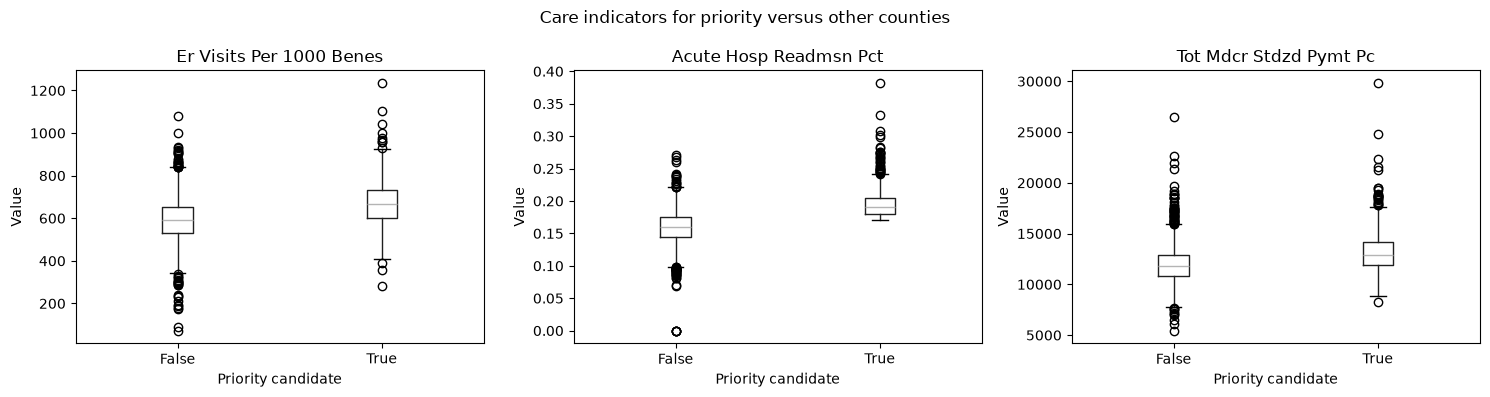

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, care_indicators):
    score_df.boxplot(column=column, by="Priority", ax=ax, grid=False)
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Priority candidate")
    ax.set_ylabel("Value")
fig.suptitle("Care indicators for priority versus other counties")
plt.tight_layout()
plt.show()

## Map need, care indicators, and service-use context

These county choropleths keep each measure separate so the map does not conceal tradeoffs in a composite. They include FQHC/RHC and outpatient visit rates as service-use context; visit rates are not direct measures of provider availability or access. Strict-priority counties are outlined on those two service-use maps so their locations can be compared directly with utilization patterns. The notebook downloads the official [2024 Census TIGER/Line county boundaries](https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_county_500k.zip) and caches them under `data/raw/` (ignored by Git). Install the small shapefile reader once with `python -m pip install -r requirements-mapping.txt`. The map separates the contiguous U.S., Alaska, and Hawaii; territories are excluded. Colors are clipped to each measure's 2nd and 98th percentiles to make county patterns easier to see; use the raw data/table for extremes.

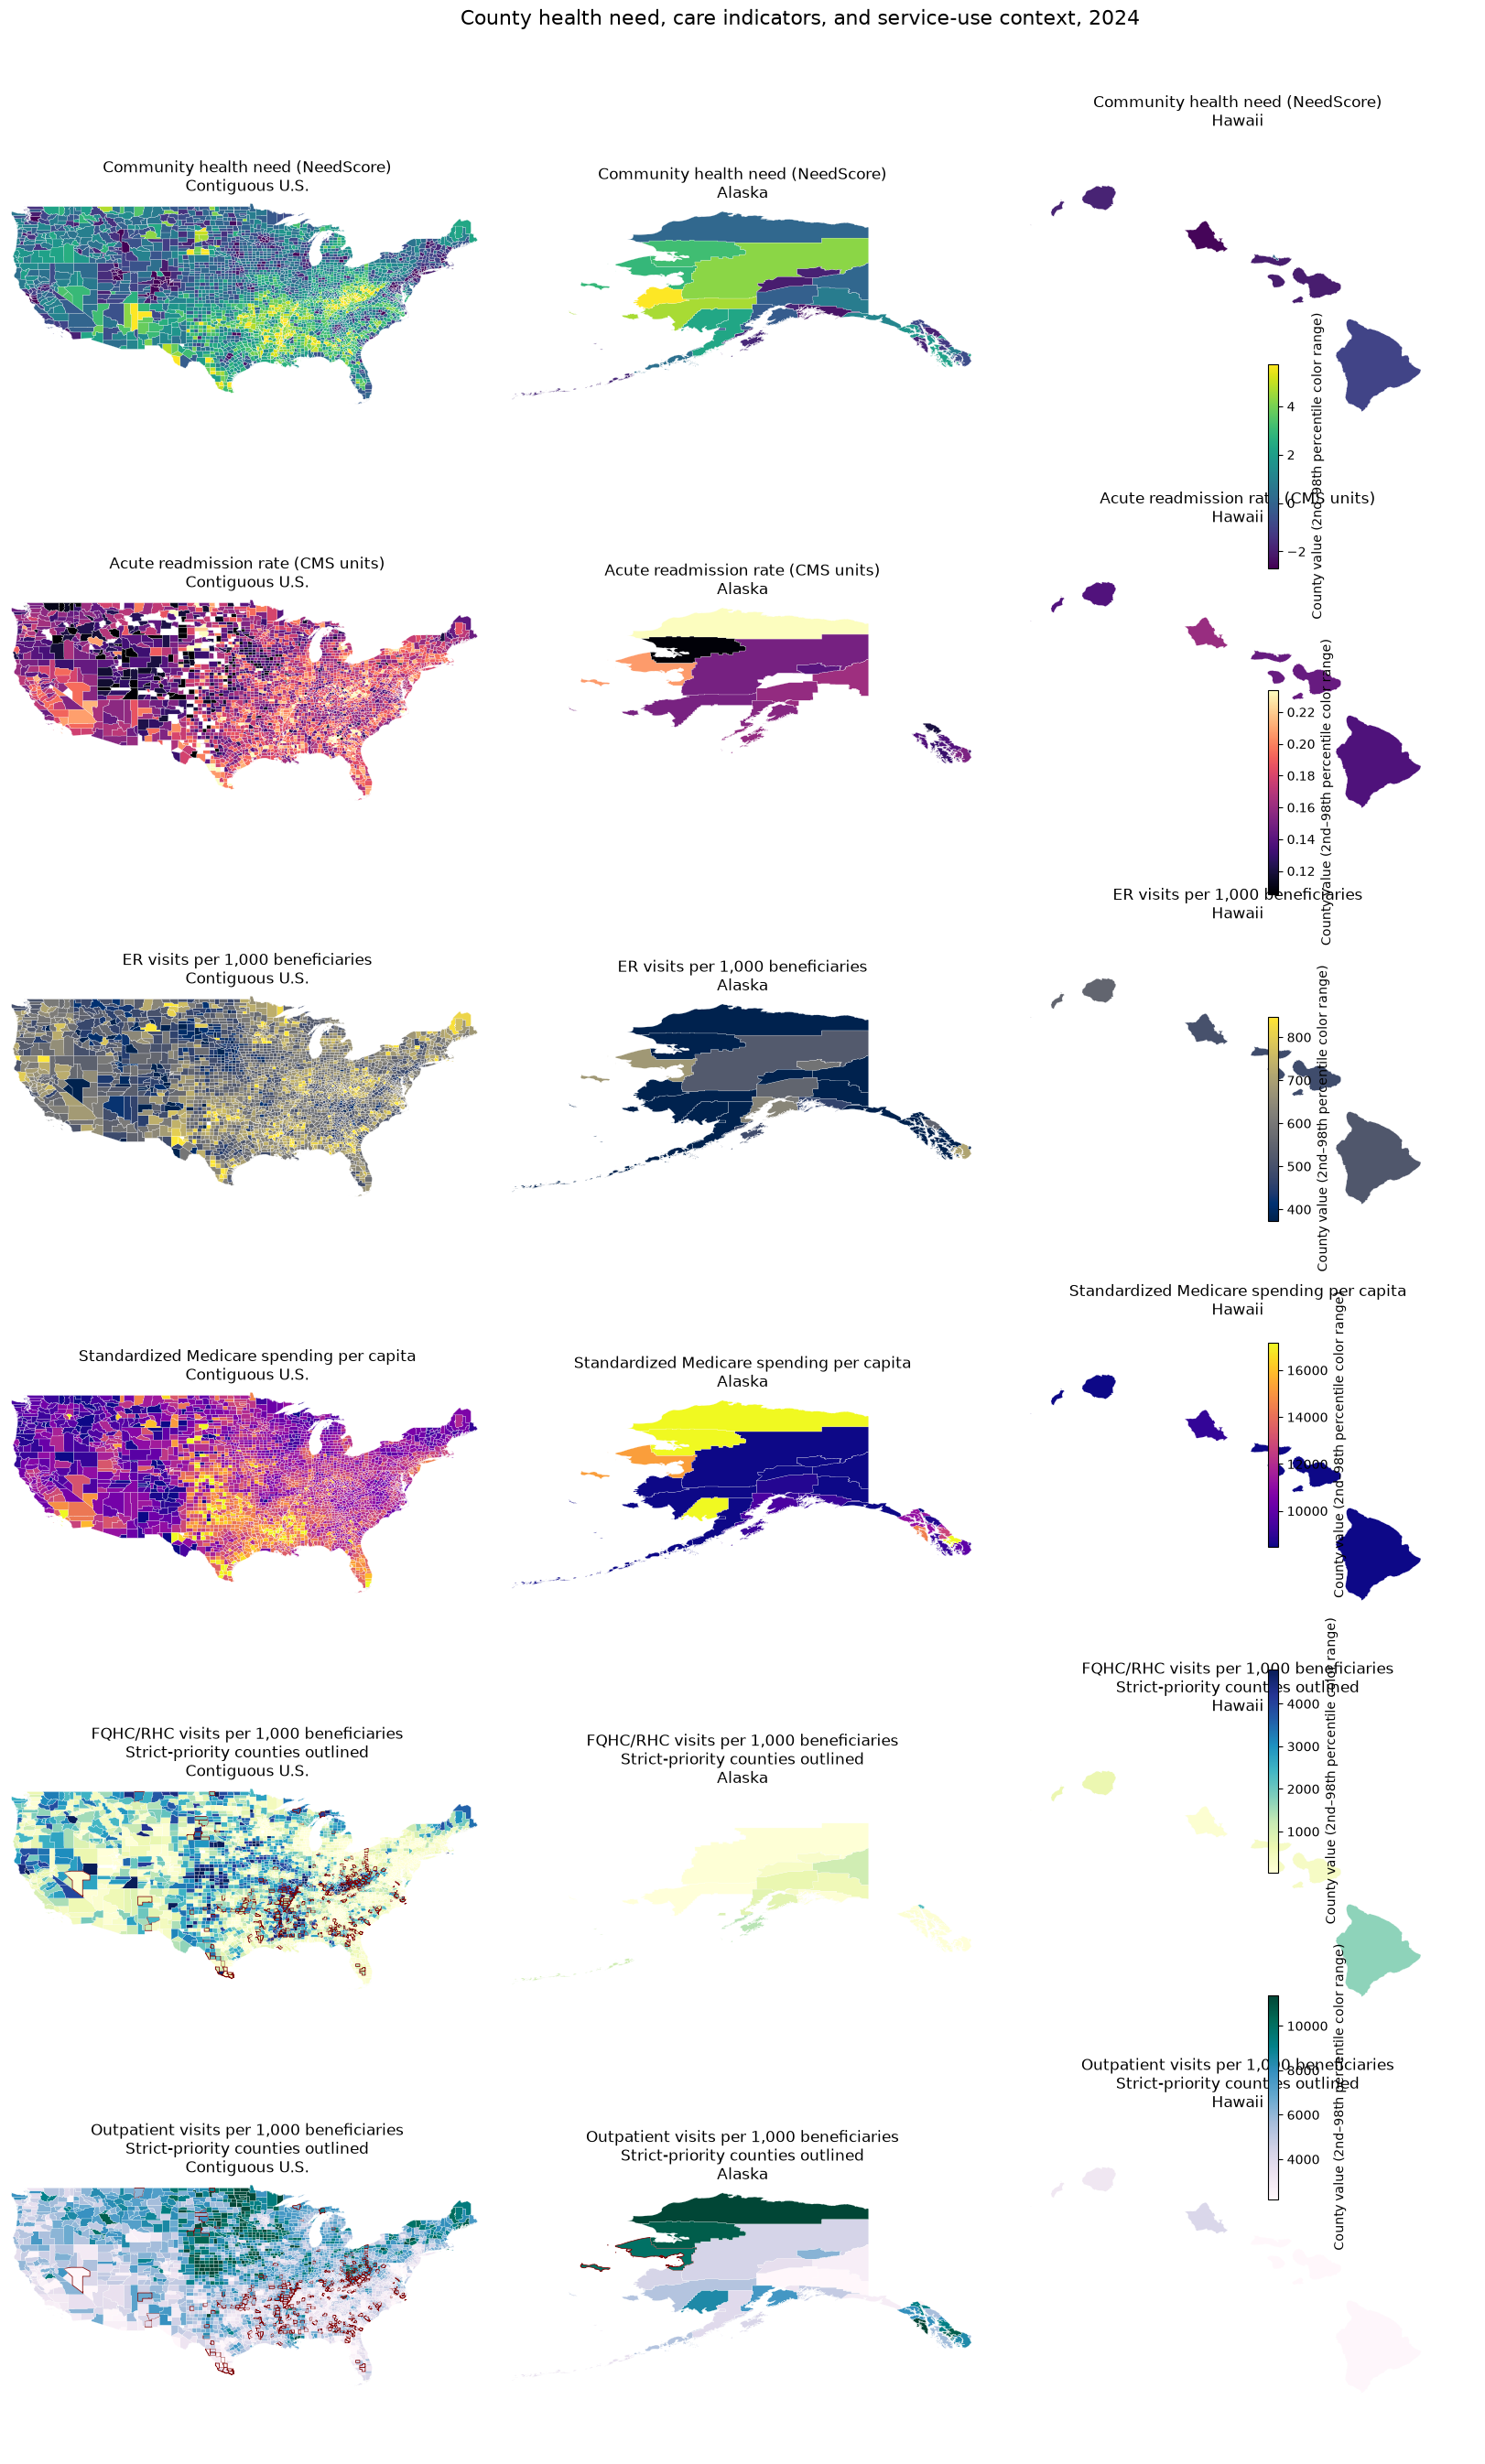

Counties with data by indicator and region:
Community health need (NeedScore):
  Contiguous U.S.: 3,107
  Alaska: 30
  Hawaii: 5
Acute readmission rate (CMS units):
  Contiguous U.S.: 2,976
  Alaska: 17
  Hawaii: 4
ER visits per 1,000 beneficiaries:
  Contiguous U.S.: 3,106
  Alaska: 30
  Hawaii: 4
Standardized Medicare spending per capita:
  Contiguous U.S.: 3,107
  Alaska: 30
  Hawaii: 4
FQHC/RHC visits per 1,000 beneficiaries:
  Contiguous U.S.: 3,091
  Alaska: 21
  Hawaii: 4
Outpatient visits per 1,000 beneficiaries:
  Contiguous U.S.: 3,107
  Alaska: 30
  Hawaii: 4


In [14]:
import ssl
import zipfile
from pathlib import Path
from urllib.request import urlopen

import certifi
import numpy as np
import shapefile
from matplotlib.cm import ScalarMappable
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon as MapPolygon

raw_dir = PROJECT_ROOT / "data/raw"
raw_dir.mkdir(parents=True, exist_ok=True)
boundary_zip = raw_dir / "cb_2024_us_county_500k.zip"
shape_path = raw_dir / "cb_2024_us_county_500k.shp"
if not boundary_zip.exists():
    boundary_url = (
        "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
        "cb_2024_us_county_500k.zip"
    )
    context = ssl.create_default_context(cafile=certifi.where())
    with urlopen(boundary_url, context=context, timeout=60) as response:
        boundary_zip.write_bytes(response.read())

if not shape_path.exists():
    with zipfile.ZipFile(boundary_zip) as archive:
        members = {Path(name).suffix.lower(): name for name in archive.namelist()}
        for extension in (".shp", ".shx", ".dbf"):
            shape_member = members.get(extension)
            if shape_member is None:
                raise FileNotFoundError(f"Missing {extension} in Census boundary archive")
            (raw_dir / f"cb_2024_us_county_500k{extension}").write_bytes(
                archive.read(shape_member)
            )

county_by_fips = analysis_df.set_index("CountyFIPS")
region_state_codes = {
    "Contiguous U.S.": None,
    "Alaska": {"02"},
    "Hawaii": {"15"},
}
territory_codes = {"60", "66", "69", "72", "78"}
region_polygons = {region: [] for region in region_state_codes}

with shapefile.Reader(str(shape_path), encoding="utf-8") as county_shapes:
    field_names = [field[0] for field in county_shapes.fields[1:]]
    for shape_record in county_shapes.iterShapeRecords():
        record = dict(zip(field_names, shape_record.record))
        state_code = str(record["STATEFP"]).zfill(2)
        county_fips = str(record["GEOID"]).zfill(5)
        if county_fips not in county_by_fips.index:
            continue
        if state_code in territory_codes:
            continue

        if state_code == "02":
            region = "Alaska"
        elif state_code == "15":
            region = "Hawaii"
        else:
            region = "Contiguous U.S."

        points = shape_record.shape.points
        part_starts = list(shape_record.shape.parts) + [len(points)]
        for start, end in zip(part_starts, part_starts[1:]):
            region_polygons[region].append((points[start:end], county_fips))

map_metrics = [
    ("NeedScore", "Community health need (NeedScore)", "viridis"),
    ("ACUTE_HOSP_READMSN_PCT", "Acute readmission rate (CMS units)", "magma"),
    ("ER_VISITS_PER_1000_BENES", "ER visits per 1,000 beneficiaries", "cividis"),
    ("TOT_MDCR_STDZD_PYMT_PC", "Standardized Medicare spending per capita", "plasma"),
("FQHC_RHC_VISITS_PER_1000_BENES", "FQHC/RHC visits per 1,000 beneficiaries", "YlGnBu"),
("OP_VISITS_PER_1000_BENES", "Outpatient visits per 1,000 beneficiaries", "PuBuGn"),
]
service_use_map_columns = {
    "FQHC_RHC_VISITS_PER_1000_BENES",
    "OP_VISITS_PER_1000_BENES",
}
strict_priority_fips = set(
    score_df.loc[score_df["StrictPriority"], "CountyFIPS"]
)
region_limits = {
    "Contiguous U.S.": (-125, -66, 24, 50),
    "Alaska": (-180, -129, 51, 72),
    "Hawaii": (-161, -154, 18, 23),
}

fig, axes = plt.subplots(len(map_metrics), 3, figsize=(18, 27))
for row, (column, title, cmap) in enumerate(map_metrics):
    values = county_by_fips[column].dropna()
    lower, upper = values.quantile([0.02, 0.98])
    norm = Normalize(vmin=lower, vmax=upper, clip=True)
    for col_index, (region, limits) in enumerate(region_limits.items()):
        ax = axes[row, col_index]
        patches = []
        patch_values = []
        edge_colors = []
        line_widths = []
        for exterior, county_fips in region_polygons[region]:
            county_value = county_by_fips.at[county_fips, column]
            if pd.notna(county_value):
                patches.append(MapPolygon(exterior, closed=True))
                patch_values.append(county_value)
                if column in service_use_map_columns and county_fips in strict_priority_fips:
                    edge_colors.append("#7f0000")
                    line_widths.append(0.55)
                else:
                    edge_colors.append("white")
                    line_widths.append(0.15)

        collection = PatchCollection(
            patches, cmap=cmap, norm=norm,
            edgecolor=edge_colors, linewidth=line_widths,
        )
        collection.set_array(np.asarray(patch_values))
        ax.add_collection(collection)
        west, east, south, north = limits
        ax.set_xlim(west, east)
        ax.set_ylim(south, north)
        ax.set_aspect("equal", adjustable="box")
        map_title = title
        if column in service_use_map_columns:
            map_title += "\nStrict-priority counties outlined"
        ax.set_title(f"{map_title}\n{region}")
        ax.set_axis_off()

    colorbar = fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap),
        ax=axes[row, :].tolist(),
        shrink=0.75,
        pad=0.02,
    )
    colorbar.set_label("County value (2nd–98th percentile color range)")

plt.suptitle("County health need, care indicators, and service-use context, 2024", y=1.01, fontsize=16)
fig.subplots_adjust(left=0.02, right=0.91, bottom=0.02, top=0.96, wspace=0.04, hspace=0.16)
plt.show()

print("Counties with data by indicator and region:")
for column, title, _ in map_metrics:
    print(f"{title}:")
    for region, polygons in region_polygons.items():
        region_fips = {fips for _, fips in polygons}
        data_count = sum(
            pd.notna(county_by_fips.at[fips, column]) for fips in region_fips
        )
        print(f"  {region}: {data_count:,}")

## Map the priority quadrants

This map shows where counties fall in the NeedScore/readmission comparison. Gray counties have no quadrant because at least one of the three CMS indicators needed for the sensitivity analysis is missing or suppressed. Comparing this map with the separate measure maps helps distinguish geographic clustering from one unusual indicator.

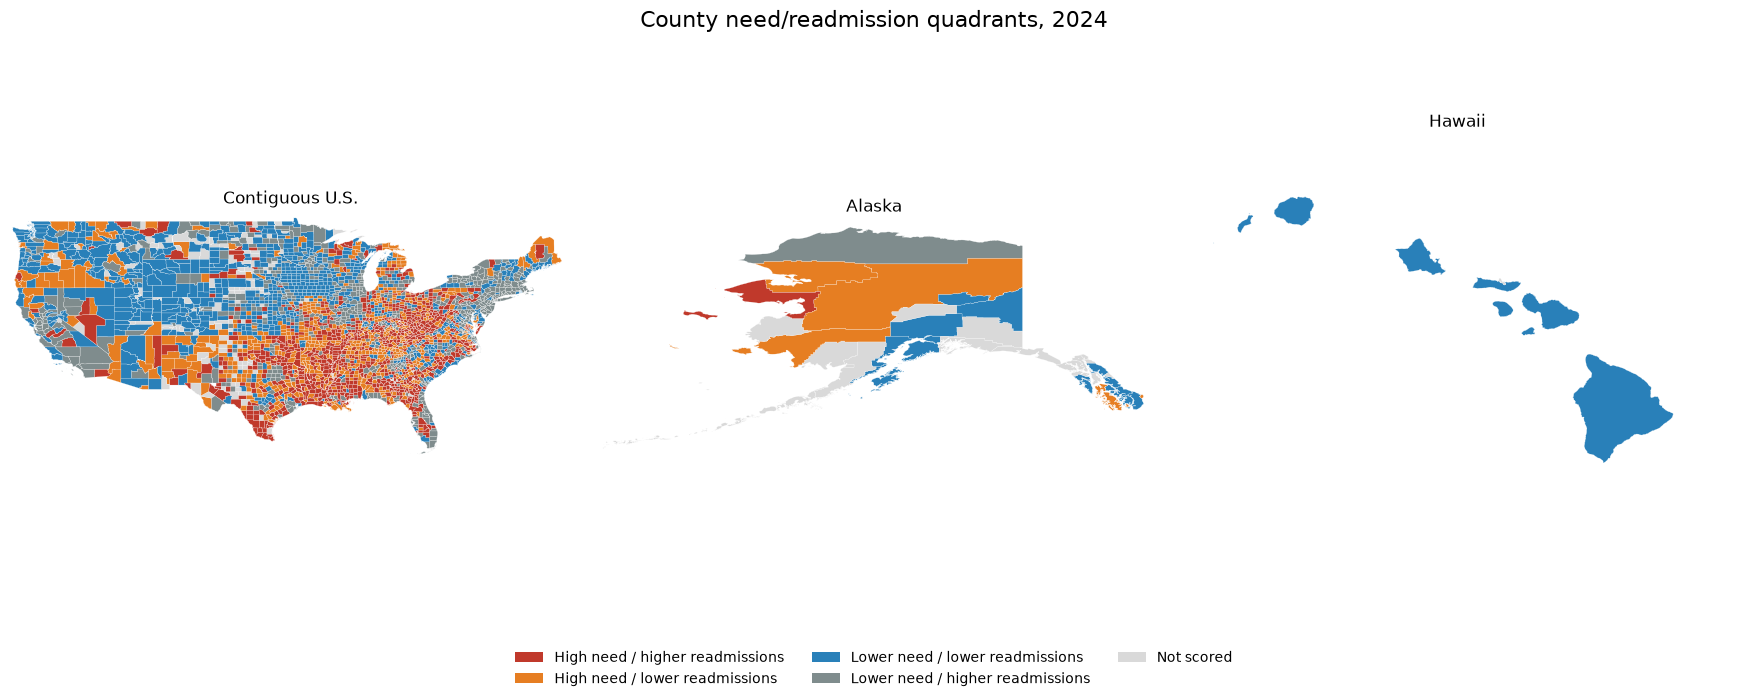

Counties scored: 2,996; not scored: 146


In [15]:
from matplotlib.patches import Patch

quadrant_colors = {
    "High need / higher readmissions": "#c0392b",
    "High need / lower readmissions": "#e67e22",
    "Lower need / lower readmissions": "#2980b9",
    "Lower need / higher readmissions": "#7f8c8d",
}
not_scored_color = "#d9d9d9"
quadrant_by_fips = score_df.set_index("CountyFIPS")["Quadrant"]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    facecolors = []
    for vertices, county_fips in region_polygons[region]:
        patches.append(MapPolygon(vertices, closed=True))
        quadrant = quadrant_by_fips.get(county_fips)
        facecolors.append(quadrant_colors.get(quadrant, not_scored_color))

    collection = PatchCollection(
        patches,
        facecolors=facecolors,
        edgecolor="white",
        linewidth=0.15,
    )
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

legend_items = [
    Patch(facecolor=color, label=label)
    for label, color in quadrant_colors.items()
]
legend_items.append(Patch(facecolor=not_scored_color, label="Not scored"))
fig.legend(handles=legend_items, loc="lower center", ncol=3, frameon=False)
fig.suptitle("County need/readmission quadrants, 2024", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.15, top=0.88, wspace=0.04)
plt.show()

print(f"Counties scored: {len(score_df):,}; not scored: {len(analysis_df) - len(score_df):,}")

## Map the stricter priority group

This view focuses on the stricter top-quartile definition: high NeedScore and high observed readmission rate. Red counties meet both cutoffs, gray counties have scores but do not meet both, and light gray counties lack complete scores. The map is a locator for further investigation, not a measure of quality or a causal explanation.

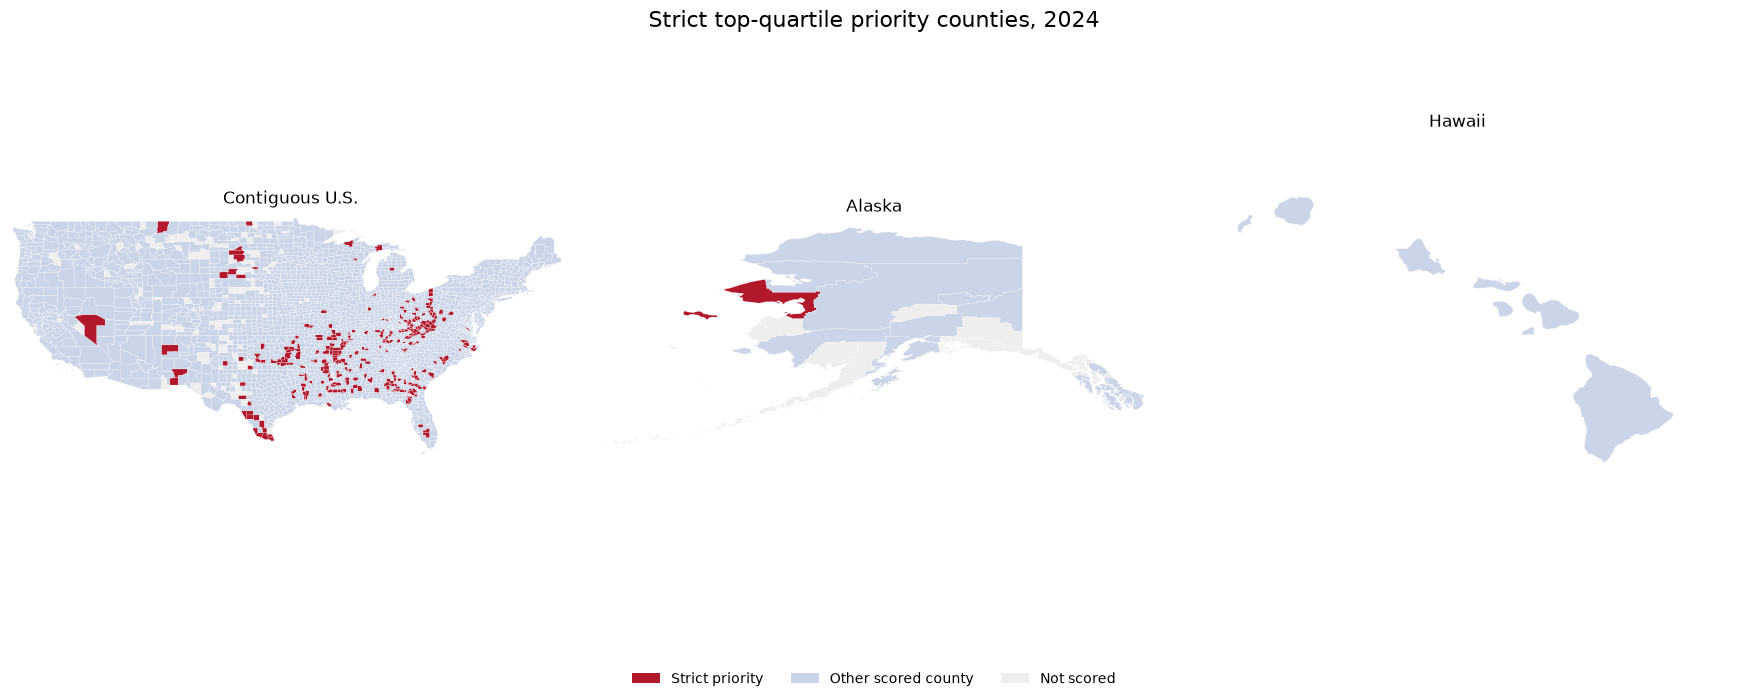

Strict priority counties mapped: 289


In [16]:
strict_by_fips = score_df.set_index("CountyFIPS")["StrictPriority"]
strict_colors = {
    "Strict priority": "#b2182b",
    "Other scored county": "#cbd5e8",
    "Not scored": "#eeeeee",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    facecolors = []
    for vertices, county_fips in region_polygons[region]:
        patches.append(MapPolygon(vertices, closed=True))
        if county_fips not in strict_by_fips.index:
            status = "Not scored"
        elif strict_by_fips.at[county_fips]:
            status = "Strict priority"
        else:
            status = "Other scored county"
        facecolors.append(strict_colors[status])

    collection = PatchCollection(
        patches,
        facecolors=facecolors,
        edgecolor="white",
        linewidth=0.15,
    )
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

strict_legend = [
    Patch(facecolor=color, label=label)
    for label, color in strict_colors.items()
]
fig.legend(handles=strict_legend, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Strict top-quartile priority counties, 2024", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.15, top=0.88, wspace=0.04)
plt.show()

print(f"Strict priority counties mapped: {int(score_df['StrictPriority'].sum()):,}")

## Summarize strict priority counties by state

The table reports both counts and shares among counties with complete data. A state with a high share may have only a few scored counties, so read the denominator alongside the percentage.

In [17]:
strict_state_profile = (
    score_df.groupby("StateAbbr")
    .agg(
        Counties_scored=("CountyFIPS", "count"),
        Strict_priority_counties=("StrictPriority", "sum"),
        Strict_priority_share=("StrictPriority", "mean"),
    )
)
strict_state_profile["Strict_priority_share_pct"] = (
    100 * strict_state_profile["Strict_priority_share"]
).round(1)
strict_state_profile.sort_values(
    ["Strict_priority_counties", "Strict_priority_share"],
    ascending=False,
).head(15).drop(columns="Strict_priority_share")

,Counties_scored,Strict_priority_counties,Strict_priority_share_pct
StateAbbr,,,
GA,151,30,19.9
KY,119,27,22.7
WV,55,26,47.3
TX,226,24,10.6
MS,81,22,27.2
AR,75,20,26.7
OK,76,20,26.3
TN,95,16,16.8
OH,88,15,17.0


## Compare service-use context across priority tiers

The CMS file also reports FQHC/RHC visits, outpatient visits, Medicare Advantage participation, and dual eligibility. These help describe how priority counties differ, but visit rates are utilization—not direct provider-supply or access measures. Higher or lower use is not inherently better. The tiers distinguish strict top-quartile priority counties, the remaining median-based priority group, and other scored counties.

In [18]:
priority_tier_order = [
    "Strict priority",
    "Median priority, not strict",
    "Other counties",
]
score_df["PriorityTier"] = "Other counties"
score_df.loc[score_df["Priority"], "PriorityTier"] = "Median priority, not strict"
score_df.loc[score_df["StrictPriority"], "PriorityTier"] = "Strict priority"
score_df["PriorityTier"] = pd.Categorical(
    score_df["PriorityTier"],
    categories=priority_tier_order,
    ordered=True,
)

context_indicators = {
    "FQHC/RHC visits per 1,000 beneficiaries": "FQHC_RHC_VISITS_PER_1000_BENES",
    "Outpatient visits per 1,000 beneficiaries": "OP_VISITS_PER_1000_BENES",
    "Medicare Advantage participation (CMS units)": "MA_PRTCPTN_RATE",
    "Dual eligibility (CMS units)": "BENE_DUAL_PCT",
}
context_rows = []
for tier in priority_tier_order:
    group = score_df.loc[score_df["PriorityTier"] == tier]
    for label, column in context_indicators.items():
        values = group[column].dropna()
        context_rows.append({
            "Priority tier": tier,
            "Indicator": label,
            "Count with data": len(values),
            "Median": values.median(),
            "25th percentile": values.quantile(0.25),
            "75th percentile": values.quantile(0.75),
        })

context_profile = pd.DataFrame(context_rows)
context_profile.round(3)

,Priority tier,Indicator,Count with data,Median,25th percentile,75th percentile
0,Strict priority,"FQHC/RHC visits per 1,000 beneficiaries",286,1558.566,799.136,2693.459
1,Strict priority,"Outpatient visits per 1,000 beneficiaries",289,4755.556,3671.706,6280.605
2,Strict priority,Medicare Advantage participation (CMS units),288,0.556,0.475,0.639
3,Strict priority,Dual eligibility (CMS units),289,0.178,0.147,0.223
4,"Median priority, not strict","FQHC/RHC visits per 1,000 beneficiaries",559,1151.820,387.107,2292.157
5,"Median priority, not strict","Outpatient visits per 1,000 beneficiaries",559,5133.095,3978.244,6726.996
6,"Median priority, not strict",Medicare Advantage participation (CMS units),559,0.525,0.442,0.606
7,"Median priority, not strict",Dual eligibility (CMS units),559,0.141,0.110,0.182
8,Other counties,"FQHC/RHC visits per 1,000 beneficiaries",2139,808.604,197.464,2251.673
9,Other counties,"Outpatient visits per 1,000 beneficiaries",2148,5795.802,4150.974,7681.424


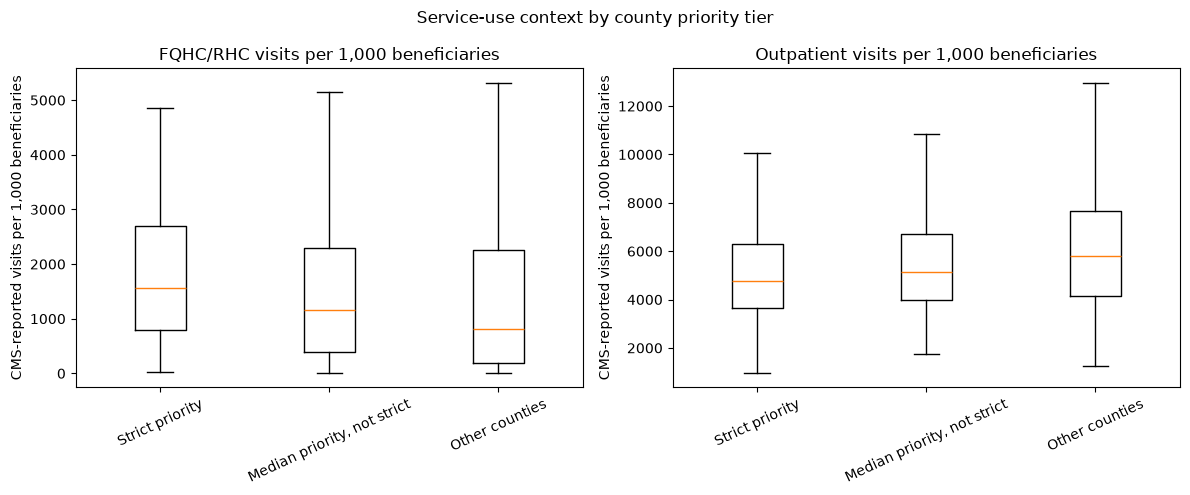

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
service_use_metrics = [
    ("FQHC_RHC_VISITS_PER_1000_BENES", "FQHC/RHC visits per 1,000 beneficiaries"),
    ("OP_VISITS_PER_1000_BENES", "Outpatient visits per 1,000 beneficiaries"),
]
for ax, (column, title) in zip(axes, service_use_metrics):
    tier_values = [
        score_df.loc[score_df["PriorityTier"] == tier, column].dropna()
        for tier in priority_tier_order
    ]
    ax.boxplot(tier_values, tick_labels=priority_tier_order, showfliers=False)
    ax.set_title(title)
    ax.set_ylabel("CMS-reported visits per 1,000 beneficiaries")
    ax.tick_params(axis="x", labelrotation=25)
fig.suptitle("Service-use context by county priority tier")
fig.tight_layout()
plt.show()

## Summarize priority candidates by state

State totals use only counties with complete values for all three CMS indicators. Priority share is more comparable than raw priority count, while the count shows the size of the flagged group. Neither is a state ranking: county size and data completeness differ.

In [20]:
state_profile = (
    score_df.groupby("StateAbbr")
    .agg(
        Counties_scored=("CountyFIPS", "count"),
        Priority_counties=("Priority", "sum"),
        Priority_share=("Priority", "mean"),
        Median_NeedScore=("NeedScore", "median"),
        Median_readmission_rate=("ACUTE_HOSP_READMSN_PCT", "median"),
    )
)
state_profile["Priority_share_pct"] = (100 * state_profile["Priority_share"]).round(1)
state_profile.sort_values(
    ["Priority_share", "Priority_counties"], ascending=False
).head(15).drop(columns="Priority_share")

,Counties_scored,Priority_counties,Median_NeedScore,Median_readmission_rate,Priority_share_pct
StateAbbr,,,,,
WV,55,44,4.054601,0.19710,80.0
MS,81,53,3.416583,0.18510,65.4
LA,64,40,3.069725,0.17785,62.5
OK,76,43,3.246952,0.17730,56.6
KY,119,64,3.325890,0.18050,53.8
OH,88,46,2.146338,0.17785,52.3
AL,67,34,3.211199,0.17430,50.7
AR,75,38,3.947524,0.17080,50.7
GA,151,70,2.044250,0.18420,46.4


## Quantify below-median service-use overlap

The maps show where visit rates occur; this comparison summarizes how often each priority tier is below the scored-county median for each measure. Each percentage uses only counties in that tier with a reported value. “Below median” describes utilization relative to this dataset, not inadequate access or unmet need.

## Check sensitivity to beneficiary counts

The denominator check above places 749 scored counties in the lowest beneficiary-count quartile, with an upper boundary of about 3,244 beneficiaries. This sensitivity check excludes that quartile and compares tier percentages using the full scored-county visit-rate medians as fixed cutoffs. Keeping the cutoffs fixed makes the comparison easier to interpret; the remaining rates still warrant caution.

## View the two service-use indicators together

This scatterplot includes only counties with both visit rates reported. Each point is a county, colored by priority tier; dashed lines mark the scored-county medians used above. Both axes use a logarithmic scale because the visit rates are right-skewed and positive in this analytic set. On a log scale, equal distances represent ratios rather than equal absolute differences. The plot describes utilization patterns, not access or care quality.

## Map combinations of service-use rates

This categorical map translates the scatterplot's median lines into four county groups: below or at/above the scored-county median on each visit-rate measure. Dark red outlines mark strict-priority counties. Gray counties lack one or both visit rates in the scored analysis. These are utilization patterns only—not access or performance ratings.

## Compare service-use patterns as shares

The map and count table show where each combination occurs. This 100% stacked chart and table show each combination's share within its priority tier, so tiers with different county counts can be compared fairly. Only counties with both visit rates reported are included.

## Build an exploratory county follow-up list

This list isolates strict-priority counties that are below the scored-county median on both visit measures. It is a starting point for checking local context—not a designation of underserved counties. The table keeps beneficiary counts and observed rates visible so small denominators and differing local circumstances can be considered.

## Compare the shortlist with HRSA primary-care shortage designations

As an additional context check, this section uses the [HRSA Primary Care HPSA detail file](https://data.hrsa.gov/DataDownload/DD_Files/BCD_HPSA_FCT_DET_PC.csv), available from the [HRSA Data Downloads catalog](https://data.hrsa.gov/data/download?data=SHORT). It flags a county when the current snapshot lists at least one **Designated** Primary Care **Geographic HPSA** or **High Needs Geographic HPSA** record under that county FIPS. Population- and facility-specific designations are excluded. The county flag does not mean the whole county is covered by a shortage designation, and no record does not prove access is adequate. HRSA refreshes this data daily, so it is a current context snapshot—not a measure aligned to the 2024 CMS data.

Active primary-care geographic HPSA records matched to 992 counties in the merged project data.


,County group,Counties,With active geographic primary-care HPSA,Share with designation (%)
0,Follow-up shortlist,62,26,41.9
1,Other strict-priority counties,227,76,33.5
2,Other scored counties,2707,792,29.3


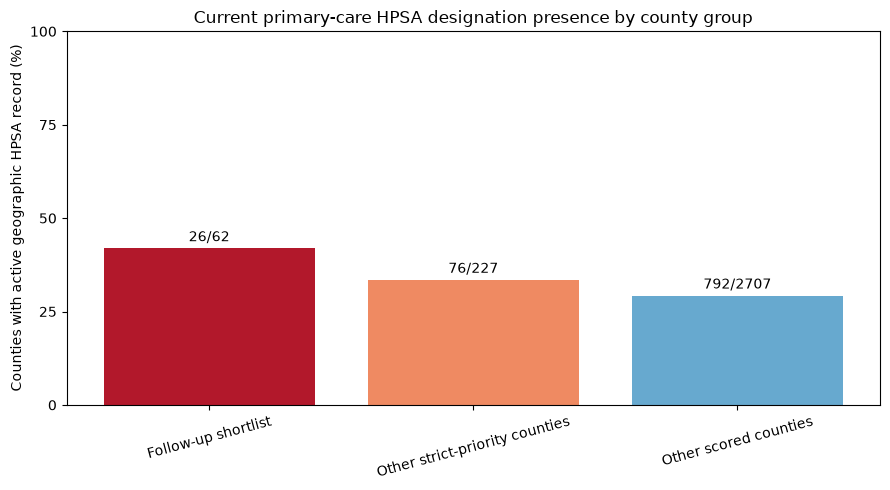

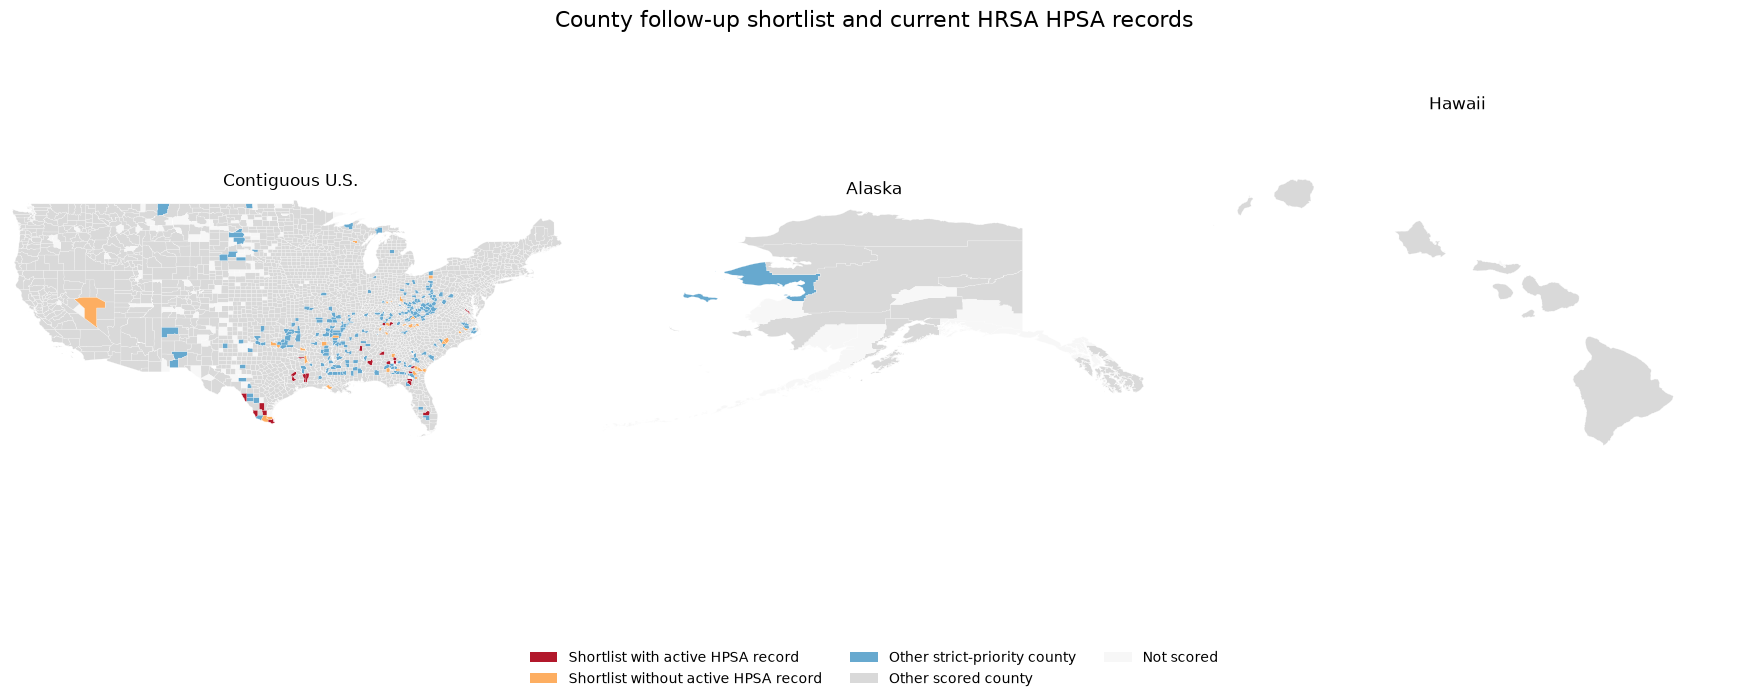

HPSAMapGroup
Shortlist with active HPSA record         26
Shortlist without active HPSA record      36
Other strict-priority county             227
Other scored county                     2707
Not scored                               146
Name: Counties, dtype: int64

,2024 need/readmission quadrant,Counties,With current geographic primary-care HPSA,Share with designation (%)
0,High need / higher readmissions,848,255,30.1
1,High need / lower readmissions,650,206,31.7
2,Lower need / higher readmissions,649,155,23.9
3,Lower need / lower readmissions,849,278,32.7


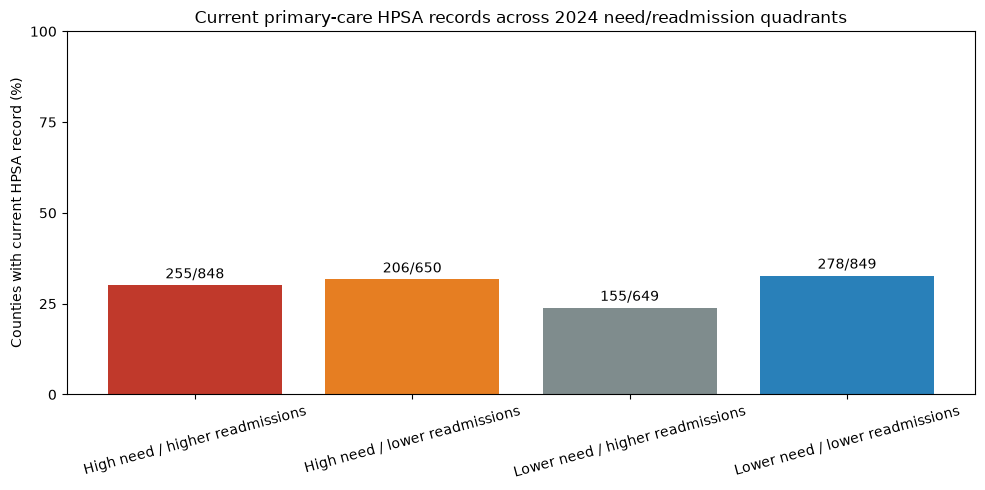

In [21]:
import ssl
from urllib.request import urlopen

import certifi
from IPython.display import display

hpsa_url = "https://data.hrsa.gov/DataDownload/DD_Files/BCD_HPSA_FCT_DET_PC.csv"
hpsa_path = PROJECT_ROOT / "data/raw/hrsa_primary_care_hpsa.csv"
hpsa_path.parent.mkdir(parents=True, exist_ok=True)
if not hpsa_path.exists():
    hpsa_context = ssl.create_default_context(cafile=certifi.where())
    with urlopen(hpsa_url, context=hpsa_context, timeout=120) as response:
        hpsa_path.write_bytes(response.read())

hpsa_columns = [
    "HPSA ID",
    "Designation Type",
    "HPSA Discipline Class",
    "HPSA Status",
    "Common State County FIPS Code",
]
hpsa_data = pd.read_csv(hpsa_path, dtype=str, usecols=hpsa_columns)
geographic_primary_hpsa = hpsa_data.loc[
    hpsa_data["HPSA Discipline Class"].str.strip().eq("Primary Care")
    & hpsa_data["HPSA Status"].str.strip().eq("Designated")
    & hpsa_data["Designation Type"].str.strip().isin(
        ["Geographic HPSA", "High Needs Geographic HPSA"]
    )
].copy()
geographic_primary_hpsa["CountyFIPS"] = (
    geographic_primary_hpsa["Common State County FIPS Code"]
    .str.strip()
    .str.zfill(5)
)
geographic_primary_hpsa = geographic_primary_hpsa.loc[
    geographic_primary_hpsa["CountyFIPS"].str.fullmatch(r"\d{5}", na=False)
    & geographic_primary_hpsa["CountyFIPS"].isin(analysis_df["CountyFIPS"])
]
hpsa_by_county = geographic_primary_hpsa.groupby("CountyFIPS").agg(
    ActivePrimaryCareGeographicHPSARecords=("HPSA ID", "nunique")
)

hpsa_scored = score_df.merge(
    hpsa_by_county,
    left_on="CountyFIPS",
    right_index=True,
    how="left",
    validate="one_to_one",
)
hpsa_scored["ActivePrimaryCareGeographicHPSARecords"] = (
    hpsa_scored["ActivePrimaryCareGeographicHPSARecords"].fillna(0).astype(int)
)
hpsa_scored["HasActivePrimaryCareGeographicHPSA"] = (
    hpsa_scored["ActivePrimaryCareGeographicHPSARecords"].gt(0)
)

hpsa_fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
hpsa_outpatient_column = "OP_VISITS_PER_1000_BENES"
hpsa_fqhc_cutoff = hpsa_scored[hpsa_fqhc_column].median()
hpsa_outpatient_cutoff = hpsa_scored[hpsa_outpatient_column].median()
hpsa_followup_mask = (
    hpsa_scored["StrictPriority"]
    & hpsa_scored[hpsa_fqhc_column].lt(hpsa_fqhc_cutoff)
    & hpsa_scored[hpsa_outpatient_column].lt(hpsa_outpatient_cutoff)
)
hpsa_group_masks = {
    "Follow-up shortlist": hpsa_followup_mask,
    "Other strict-priority counties": hpsa_scored["StrictPriority"] & ~hpsa_followup_mask,
    "Other scored counties": ~hpsa_scored["StrictPriority"],
}
hpsa_profile_rows = []
for label, mask in hpsa_group_masks.items():
    group = hpsa_scored.loc[mask]
    hpsa_count = int(group["HasActivePrimaryCareGeographicHPSA"].sum())
    hpsa_profile_rows.append({
        "County group": label,
        "Counties": len(group),
        "With active geographic primary-care HPSA": hpsa_count,
        "Share with designation (%)": 100 * hpsa_count / len(group) if len(group) else np.nan,
    })
hpsa_profile = pd.DataFrame(hpsa_profile_rows)
print(
    f"Active primary-care geographic HPSA records matched to "
    f"{len(hpsa_by_county):,} counties in the merged project data."
)
display(hpsa_profile.round(1))

fig, ax = plt.subplots(figsize=(9, 5))
hpsa_bar_colors = ["#b2182b", "#ef8a62", "#67a9cf"]
bars = ax.bar(
    hpsa_profile["County group"],
    hpsa_profile["Share with designation (%)"],
    color=hpsa_bar_colors,
)
for bar, (_, row) in zip(bars, hpsa_profile.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{int(row['With active geographic primary-care HPSA'])}/{int(row['Counties'])}",
        ha="center",
        va="bottom",
    )
ax.set_ylabel("Counties with active geographic HPSA record (%)")
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100])
ax.tick_params(axis="x", labelrotation=15)
ax.set_title("Current primary-care HPSA designation presence by county group")
fig.tight_layout()
plt.show()

from matplotlib.collections import PatchCollection
from matplotlib.patches import Patch, Polygon as MapPolygon

hpsa_scored["FollowUpCandidate"] = hpsa_followup_mask.to_numpy()
hpsa_scored["HPSAMapGroup"] = "Other scored county"
hpsa_scored.loc[hpsa_scored["StrictPriority"], "HPSAMapGroup"] = "Other strict-priority county"
hpsa_scored.loc[
    hpsa_scored["FollowUpCandidate"]
    & hpsa_scored["HasActivePrimaryCareGeographicHPSA"],
    "HPSAMapGroup",
] = "Shortlist with active HPSA record"
hpsa_scored.loc[
    hpsa_scored["FollowUpCandidate"]
    & ~hpsa_scored["HasActivePrimaryCareGeographicHPSA"],
    "HPSAMapGroup",
] = "Shortlist without active HPSA record"
hpsa_map_group_by_fips = hpsa_scored.set_index("CountyFIPS")["HPSAMapGroup"]
hpsa_map_colors = {
    "Shortlist with active HPSA record": "#b2182b",
    "Shortlist without active HPSA record": "#fdae61",
    "Other strict-priority county": "#67a9cf",
    "Other scored county": "#d9d9d9",
    "Not scored": "#f7f7f7",
}
hpsa_map_group_order = list(hpsa_map_colors)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    facecolors = []
    for vertices, county_fips in region_polygons[region]:
        patches.append(MapPolygon(vertices, closed=True))
        group = hpsa_map_group_by_fips.get(county_fips, "Not scored")
        facecolors.append(hpsa_map_colors[group])

    collection = PatchCollection(
        patches,
        facecolors=facecolors,
        edgecolor="white",
        linewidth=0.15,
    )
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

hpsa_map_legend = [
    Patch(facecolor=hpsa_map_colors[group], label=group)
    for group in hpsa_map_group_order
]
fig.legend(handles=hpsa_map_legend, loc="lower center", ncol=3, frameon=False)
fig.suptitle("County follow-up shortlist and current HRSA HPSA records", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.20, top=0.88, wspace=0.04)
plt.show()

hpsa_map_counts = hpsa_scored["HPSAMapGroup"].value_counts()
hpsa_map_counts.loc["Not scored"] = len(analysis_df) - len(score_df)
display(hpsa_map_counts.reindex(hpsa_map_group_order, fill_value=0).rename("Counties"))

quadrant_order = [
    "High need / higher readmissions",
    "High need / lower readmissions",
    "Lower need / higher readmissions",
    "Lower need / lower readmissions",
]
quadrant_colors_for_hpsa = {
    "High need / higher readmissions": "#c0392b",
    "High need / lower readmissions": "#e67e22",
    "Lower need / higher readmissions": "#7f8c8d",
    "Lower need / lower readmissions": "#2980b9",
}
hpsa_quadrant_rows = []
for quadrant in quadrant_order:
    group = hpsa_scored.loc[hpsa_scored["Quadrant"] == quadrant]
    designated = int(group["HasActivePrimaryCareGeographicHPSA"].sum())
    hpsa_quadrant_rows.append({
        "2024 need/readmission quadrant": quadrant,
        "Counties": len(group),
        "With current geographic primary-care HPSA": designated,
        "Share with designation (%)": 100 * designated / len(group) if len(group) else np.nan,
    })
hpsa_quadrant_profile = pd.DataFrame(hpsa_quadrant_rows)
display(hpsa_quadrant_profile.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(
    hpsa_quadrant_profile["2024 need/readmission quadrant"],
    hpsa_quadrant_profile["Share with designation (%)"],
    color=[quadrant_colors_for_hpsa[q] for q in quadrant_order],
)
for bar, (_, row) in zip(bars, hpsa_quadrant_profile.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{int(row['With current geographic primary-care HPSA'])}/{int(row['Counties'])}",
        ha="center",
        va="bottom",
    )
ax.set_ylabel("Counties with current HPSA record (%)")
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100])
ax.tick_params(axis="x", labelrotation=15)
ax.set_title("Current primary-care HPSA records across 2024 need/readmission quadrants")
fig.tight_layout()
plt.show()

In [22]:
followup_fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
followup_outpatient_column = "OP_VISITS_PER_1000_BENES"
followup_cutoffs = score_df[
    [followup_fqhc_column, followup_outpatient_column]
].median()
followup_mask = (
    score_df["StrictPriority"]
    & score_df[followup_fqhc_column].lt(followup_cutoffs[followup_fqhc_column])
    & score_df[followup_outpatient_column].lt(followup_cutoffs[followup_outpatient_column])
)
followup_counties = score_df.loc[followup_mask].copy()
print(
    f"Exploratory follow-up counties: {len(followup_counties)} of "
    f"{int(score_df['StrictPriority'].sum())} strict-priority counties."
)
print(
    f"Below-median cutoffs: FQHC/RHC = {followup_cutoffs[followup_fqhc_column]:,.1f}; "
    f"outpatient = {followup_cutoffs[followup_outpatient_column]:,.1f} visits per 1,000 beneficiaries."
)
followup_counties.sort_values("NeedScore", ascending=False)[
    [
        "StateAbbr", "CountyName", "CountyFIPS", "BENES_TOTAL_CNT", "NeedScore",
        "ACUTE_HOSP_READMSN_PCT", followup_fqhc_column, followup_outpatient_column,
    ]
].head(15).round(3)

Exploratory follow-up counties: 62 of 289 strict-priority counties.
Below-median cutoffs: FQHC/RHC = 980.8; outpatient = 5,564.9 visits per 1,000 beneficiaries.


,StateAbbr,CountyName,CountyFIPS,BENES_TOTAL_CNT,NeedScore,ACUTE_HOSP_READMSN_PCT,FQHC_RHC_VISITS_PER_1000_BENES,OP_VISITS_PER_1000_BENES
164,AR,St. Francis,05123,5303.0,5.761,0.210,966.701,3919.875
389,GA,Atkinson,13003,1566.0,5.362,0.202,713.235,4857.843
2698,TX,Newton,48351,3108.0,5.294,0.201,724.374,3747.153
2453,TN,Fentress,47049,6318.0,5.284,0.193,271.092,2666.449
53,AL,Dallas,01047,10288.0,5.277,0.203,356.444,3087.556
2775,TX,Zapata,48505,2210.0,4.983,0.299,941.767,2473.896
2176,OK,Marshall,40095,4431.0,4.687,0.199,846.798,4338.217
2841,VA,Emporia,51595,1344.0,4.656,0.216,305.221,3341.366
2472,TN,Jackson,47087,3295.0,4.655,0.218,796.781,3371.563
2333,SC,Dillon,45033,7156.0,4.550,0.190,761.832,4222.008


In [23]:
share_fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
share_outpatient_column = "OP_VISITS_PER_1000_BENES"
share_pattern_labels = [
    "Below both medians",
    "FQHC/RHC below; outpatient at/above",
    "FQHC/RHC at/above; outpatient below",
    "At/above both medians",
]
share_pattern_colors = ["#762a83", "#af8dc3", "#7fbf7b", "#1b7837"]
share_cutoffs = score_df[[share_fqhc_column, share_outpatient_column]].median()
share_df = score_df.dropna(
    subset=[share_fqhc_column, share_outpatient_column]
).copy()
share_conditions = [
    share_df[share_fqhc_column].lt(share_cutoffs[share_fqhc_column])
    & share_df[share_outpatient_column].lt(share_cutoffs[share_outpatient_column]),
    share_df[share_fqhc_column].lt(share_cutoffs[share_fqhc_column])
    & share_df[share_outpatient_column].ge(share_cutoffs[share_outpatient_column]),
    share_df[share_fqhc_column].ge(share_cutoffs[share_fqhc_column])
    & share_df[share_outpatient_column].lt(share_cutoffs[share_outpatient_column]),
]
share_df["ServiceUsePattern"] = np.select(
    share_conditions,
    share_pattern_labels[:3],
    default=share_pattern_labels[3],
)

pattern_counts = pd.crosstab(
    share_df["PriorityTier"],
    share_df["ServiceUsePattern"],
).reindex(
    index=priority_tier_order,
    columns=share_pattern_labels,
    fill_value=0,
)
pattern_shares = pattern_counts.div(pattern_counts.sum(axis=1), axis=0) * 100

pattern_summary_rows = []
for tier in priority_tier_order:
    tier_total = int(pattern_counts.loc[tier].sum())
    for pattern in share_pattern_labels:
        count = int(pattern_counts.loc[tier, pattern])
        pattern_summary_rows.append({
            "Priority tier": tier,
            "Service-use pattern": pattern,
            "Count": count,
            "Tier total": tier_total,
            "Share within tier (%)": pattern_shares.loc[tier, pattern],
        })
pattern_summary = pd.DataFrame(pattern_summary_rows)
pattern_summary.round(1)

,Priority tier,Service-use pattern,Count,Tier total,Share within tier (%)
0,Strict priority,Below both medians,62,286,21.7
1,Strict priority,FQHC/RHC below; outpatient at/above,30,286,10.5
2,Strict priority,FQHC/RHC at/above; outpatient below,128,286,44.8
3,Strict priority,At/above both medians,66,286,23.1
4,"Median priority, not strict",Below both medians,169,559,30.2
5,"Median priority, not strict",FQHC/RHC below; outpatient at/above,84,559,15.0
6,"Median priority, not strict",FQHC/RHC at/above; outpatient below,151,559,27.0
7,"Median priority, not strict",At/above both medians,155,559,27.7
8,Other counties,Below both medians,671,2139,31.4
9,Other counties,FQHC/RHC below; outpatient at/above,476,2139,22.3


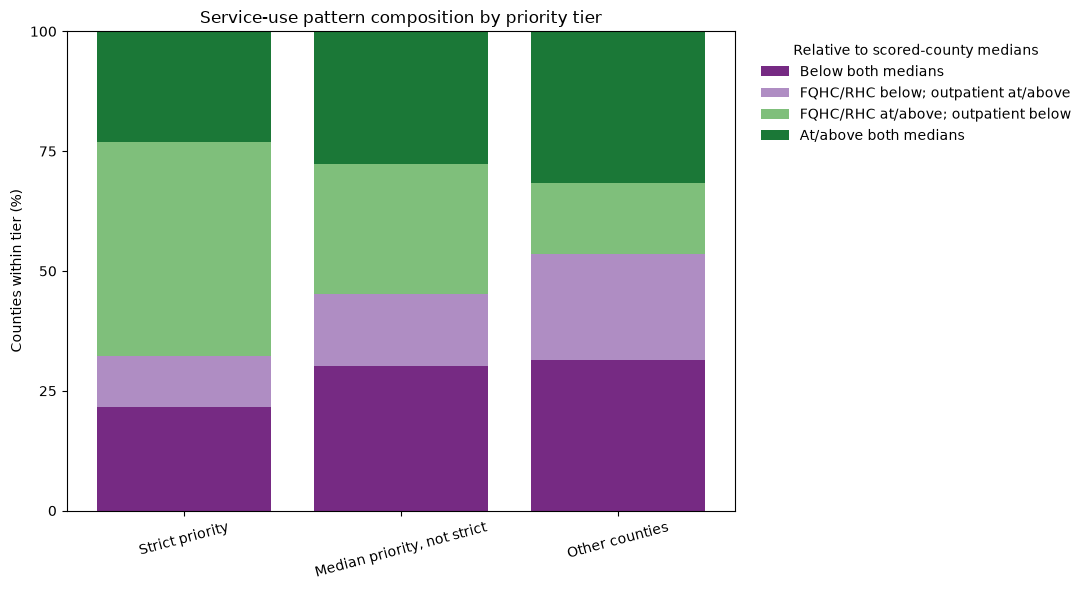

In [24]:
fig, ax = plt.subplots(figsize=(11, 6))
bottom = np.zeros(len(priority_tier_order))
for pattern, color in zip(share_pattern_labels, share_pattern_colors):
    shares = pattern_shares.loc[priority_tier_order, pattern].to_numpy()
    ax.bar(
        priority_tier_order,
        shares,
        bottom=bottom,
        color=color,
        label=pattern,
    )
    bottom += shares
ax.set_ylabel("Counties within tier (%)")
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100])
ax.tick_params(axis="x", labelrotation=15)
ax.set_title("Service-use pattern composition by priority tier")
ax.legend(title="Relative to scored-county medians", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

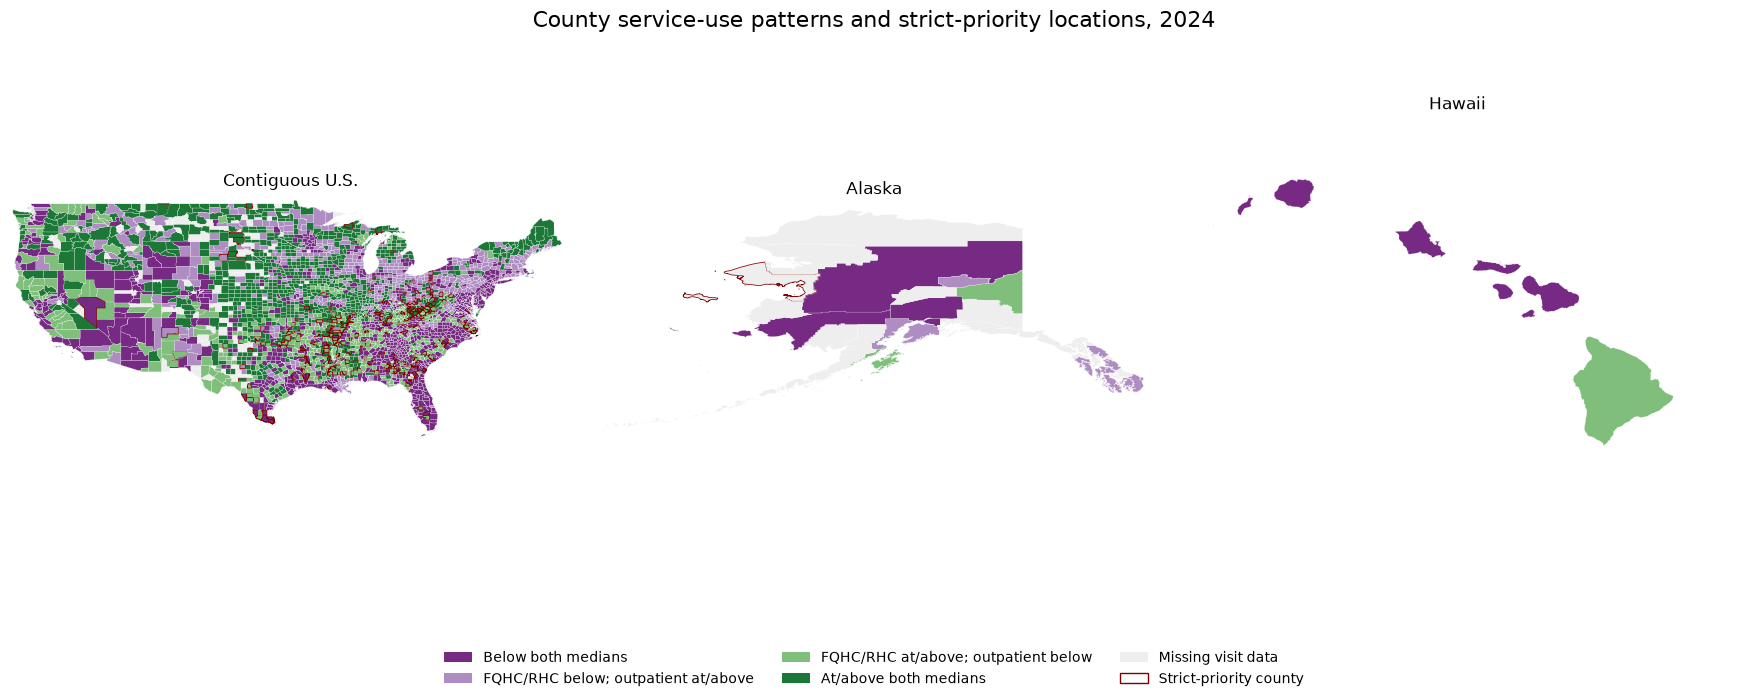

Counties mapped by service-use pattern: 2,984
ServiceUsePattern            Below both medians  \
PriorityTier                                      
Strict priority                              62   
Median priority, not strict                 169   
Other counties                              671   

ServiceUsePattern            FQHC/RHC below; outpatient at/above  \
PriorityTier                                                       
Strict priority                                               30   
Median priority, not strict                                   84   
Other counties                                               476   

ServiceUsePattern            FQHC/RHC at/above; outpatient below  \
PriorityTier                                                       
Strict priority                                              128   
Median priority, not strict                                  151   
Other counties                                               313   

ServiceUsePatter

In [25]:
fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
outpatient_column = "OP_VISITS_PER_1000_BENES"
service_map_cutoffs = score_df[[fqhc_column, outpatient_column]].median()
service_map_df = score_df.dropna(
    subset=[fqhc_column, outpatient_column]
).copy()

service_pattern_labels = [
    "Below both medians",
    "FQHC/RHC below; outpatient at/above",
    "FQHC/RHC at/above; outpatient below",
    "At/above both medians",
]
service_conditions = [
    service_map_df[fqhc_column].lt(service_map_cutoffs[fqhc_column])
    & service_map_df[outpatient_column].lt(service_map_cutoffs[outpatient_column]),
    service_map_df[fqhc_column].lt(service_map_cutoffs[fqhc_column])
    & service_map_df[outpatient_column].ge(service_map_cutoffs[outpatient_column]),
    service_map_df[fqhc_column].ge(service_map_cutoffs[fqhc_column])
    & service_map_df[outpatient_column].lt(service_map_cutoffs[outpatient_column]),
]
service_map_df["ServiceUsePattern"] = np.select(
    service_conditions,
    service_pattern_labels[:3],
    default=service_pattern_labels[3],
)
service_pattern_colors = {
    "Below both medians": "#762a83",
    "FQHC/RHC below; outpatient at/above": "#af8dc3",
    "FQHC/RHC at/above; outpatient below": "#7fbf7b",
    "At/above both medians": "#1b7837",
    "Missing visit data": "#eeeeee",
}
service_pattern_by_fips = service_map_df.set_index("CountyFIPS")["ServiceUsePattern"]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    facecolors = []
    edge_colors = []
    line_widths = []
    for vertices, county_fips in region_polygons[region]:
        patches.append(MapPolygon(vertices, closed=True))
        pattern = service_pattern_by_fips.get(county_fips, "Missing visit data")
        facecolors.append(service_pattern_colors[pattern])
        if county_fips in strict_priority_fips:
            edge_colors.append("#7f0000")
            line_widths.append(0.55)
        else:
            edge_colors.append("white")
            line_widths.append(0.15)

    collection = PatchCollection(
        patches,
        facecolors=facecolors,
        edgecolor=edge_colors,
        linewidth=line_widths,
    )
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

service_map_legend = [
    Patch(facecolor=service_pattern_colors[label], label=label)
    for label in service_pattern_labels
]
service_map_legend.append(
    Patch(facecolor=service_pattern_colors["Missing visit data"], label="Missing visit data")
)
service_map_legend.append(
    Patch(facecolor="none", edgecolor="#7f0000", label="Strict-priority county")
)
fig.legend(
    handles=service_map_legend,
    loc="lower center",
    ncol=3,
    frameon=False,
)
fig.suptitle("County service-use patterns and strict-priority locations, 2024", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.20, top=0.88, wspace=0.04)
plt.show()

print(f"Counties mapped by service-use pattern: {len(service_map_df):,}")
print(
    service_map_df.groupby(["PriorityTier", "ServiceUsePattern"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=priority_tier_order, columns=service_pattern_labels, fill_value=0)
)

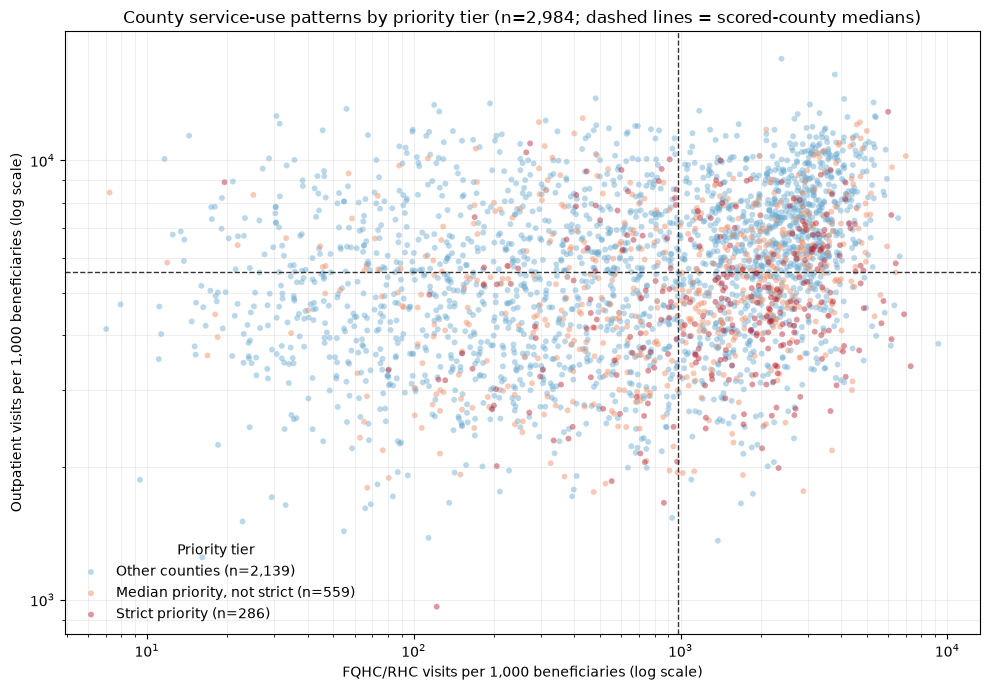

Counties shown with both visit rates: 2,984


In [26]:
fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
outpatient_column = "OP_VISITS_PER_1000_BENES"
scatter_cutoffs = score_df[[fqhc_column, outpatient_column]].median()
service_scatter_df = score_df.dropna(
    subset=[fqhc_column, outpatient_column]
)
scatter_tier_order = [
    "Other counties",
    "Median priority, not strict",
    "Strict priority",
]
tier_colors = {
    "Strict priority": "#b2182b",
    "Median priority, not strict": "#ef8a62",
    "Other counties": "#67a9cf",
}

fig, ax = plt.subplots(figsize=(10, 7))
for tier in scatter_tier_order:
    group = service_scatter_df.loc[service_scatter_df["PriorityTier"] == tier]
    ax.scatter(
        group[fqhc_column],
        group[outpatient_column],
        s=18,
        alpha=0.45,
        color=tier_colors[tier],
        edgecolors="none",
        label=f"{tier} (n={len(group):,})",
    )

ax.axvline(
    scatter_cutoffs[fqhc_column],
    color="#333333",
    linestyle="--",
    linewidth=1,
)
ax.axhline(
    scatter_cutoffs[outpatient_column],
    color="#333333",
    linestyle="--",
    linewidth=1,
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("FQHC/RHC visits per 1,000 beneficiaries (log scale)")
ax.set_ylabel("Outpatient visits per 1,000 beneficiaries (log scale)")
ax.set_title(
    f"County service-use patterns by priority tier "
    f"(n={len(service_scatter_df):,}; dashed lines = scored-county medians)"
)
ax.legend(title="Priority tier", frameon=False)
ax.grid(alpha=0.2, which="both")
fig.tight_layout()
plt.show()
print(f"Counties shown with both visit rates: {len(service_scatter_df):,}")

In [27]:
lowest_beneficiary_quartile = score_df["BeneficiaryCountQuartile"].cat.categories[0]
higher_beneficiary_mask = score_df["BeneficiaryCountQuartile"].cat.codes > 0
higher_beneficiary_df = score_df.loc[higher_beneficiary_mask]
sensitivity_indicators = {
    "FQHC_RHC_VISITS_PER_1000_BENES": "FQHC/RHC visits per 1,000 beneficiaries",
    "OP_VISITS_PER_1000_BENES": "Outpatient visits per 1,000 beneficiaries",
}
sensitivity_cutoffs = score_df[list(sensitivity_indicators)].median()
denominator_sensitivity_rows = []

for tier in priority_tier_order:
    tier_rows = higher_beneficiary_df.loc[
        higher_beneficiary_df["PriorityTier"] == tier
    ]
    full_tier_rows = score_df.loc[score_df["PriorityTier"] == tier]
    for column, label in sensitivity_indicators.items():
        values = tier_rows[column].dropna()
        full_values = full_tier_rows[column].dropna()
        below_count = int(values.lt(sensitivity_cutoffs[column]).sum())
        full_below_count = int(full_values.lt(sensitivity_cutoffs[column]).sum())
        full_below_pct = 100 * full_below_count / len(full_values) if len(full_values) else np.nan
        below_pct = 100 * below_count / len(values) if len(values) else np.nan
        denominator_sensitivity_rows.append({
            "Priority tier": tier,
            "Indicator": label,
            "Full-sample count": len(full_values),
            "Full-sample below median (%)": full_below_pct,
            "Count after excluding lowest quartile": len(values),
            "Below median count": below_count,
            "Below median (%) after exclusion": below_pct,
            "Change (percentage points)": below_pct - full_below_pct,
        })

denominator_sensitivity_profile = pd.DataFrame(denominator_sensitivity_rows)
print(
    f"Excluded {int((~higher_beneficiary_mask).sum()):,} counties with "
    f"beneficiary counts in the lowest quartile (through "
    f"{lowest_beneficiary_quartile.right:,.0f})."
)
denominator_sensitivity_profile.round(2)

Excluded 749 counties with beneficiary counts in the lowest quartile (through 3,244).


,Priority tier,Indicator,Full-sample count,Full-sample below median (%),Count after excluding lowest quartile,Below median count,Below median (%) after exclusion,Change (percentage points)
0,Strict priority,"FQHC/RHC visits per 1,000 beneficiaries",286,32.17,183,70,38.25,6.08
1,Strict priority,"Outpatient visits per 1,000 beneficiaries",289,66.09,183,123,67.21,1.12
2,"Median priority, not strict","FQHC/RHC visits per 1,000 beneficiaries",559,45.26,451,235,52.11,6.85
3,"Median priority, not strict","Outpatient visits per 1,000 beneficiaries",559,57.25,451,271,60.09,2.84
4,Other counties,"FQHC/RHC visits per 1,000 beneficiaries",2139,53.62,1611,1049,65.11,11.49
5,Other counties,"Outpatient visits per 1,000 beneficiaries",2148,45.95,1613,836,51.83,5.88


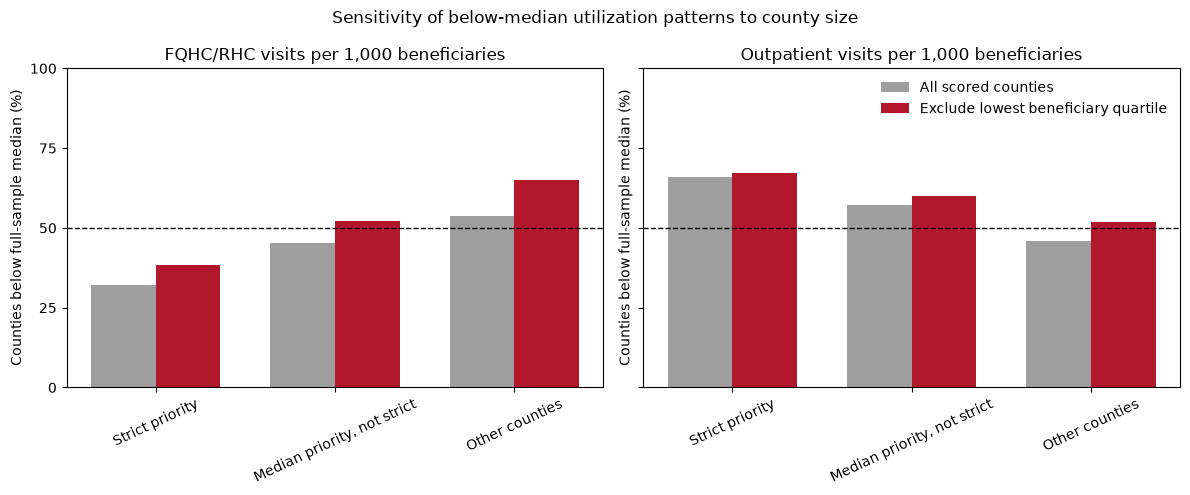

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
x = np.arange(len(priority_tier_order))
bar_width = 0.36
for ax, (column, label) in zip(axes, sensitivity_indicators.items()):
    sensitivity = denominator_sensitivity_profile.loc[
        denominator_sensitivity_profile["Indicator"] == label
    ].set_index("Priority tier").reindex(priority_tier_order)
    ax.bar(
        x - bar_width / 2,
        sensitivity["Full-sample below median (%)"],
        width=bar_width,
        color="#9e9e9e",
        label="All scored counties",
    )
    ax.bar(
        x + bar_width / 2,
        sensitivity["Below median (%) after exclusion"],
        width=bar_width,
        color="#b2182b",
        label="Exclude lowest beneficiary quartile",
    )
    ax.axhline(50, color="black", linestyle="--", linewidth=1)
    ax.set_title(label)
    ax.set_ylabel("Counties below full-sample median (%)")
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_xticks(x)
    ax.set_xticklabels(priority_tier_order, rotation=25)
axes[1].legend(frameon=False, loc="best")
fig.suptitle("Sensitivity of below-median utilization patterns to county size")
fig.tight_layout()
plt.show()

In [29]:
below_median_rows = []
service_use_labels = {
    "FQHC_RHC_VISITS_PER_1000_BENES": "FQHC/RHC visits per 1,000 beneficiaries",
    "OP_VISITS_PER_1000_BENES": "Outpatient visits per 1,000 beneficiaries",
}
service_use_cutoffs = score_df[list(service_use_labels)].median()

for tier in priority_tier_order:
    tier_rows = score_df.loc[score_df["PriorityTier"] == tier]
    for column, label in service_use_labels.items():
        values = tier_rows[column].dropna()
        below_count = int(values.lt(service_use_cutoffs[column]).sum())
        below_median_rows.append({
            "Priority tier": tier,
            "Indicator": label,
            "Scored-county median": service_use_cutoffs[column],
            "Count with data": len(values),
            "Count below median": below_count,
            "Below median (%)": 100 * below_count / len(values) if len(values) else np.nan,
        })

below_median_profile = pd.DataFrame(below_median_rows)
below_median_profile.round(2)

,Priority tier,Indicator,Scored-county median,Count with data,Count below median,Below median (%)
0,Strict priority,"FQHC/RHC visits per 1,000 beneficiaries",980.75,286,92,32.17
1,Strict priority,"Outpatient visits per 1,000 beneficiaries",5564.87,289,191,66.09
2,"Median priority, not strict","FQHC/RHC visits per 1,000 beneficiaries",980.75,559,253,45.26
3,"Median priority, not strict","Outpatient visits per 1,000 beneficiaries",5564.87,559,320,57.25
4,Other counties,"FQHC/RHC visits per 1,000 beneficiaries",980.75,2139,1147,53.62
5,Other counties,"Outpatient visits per 1,000 beneficiaries",5564.87,2148,987,45.95


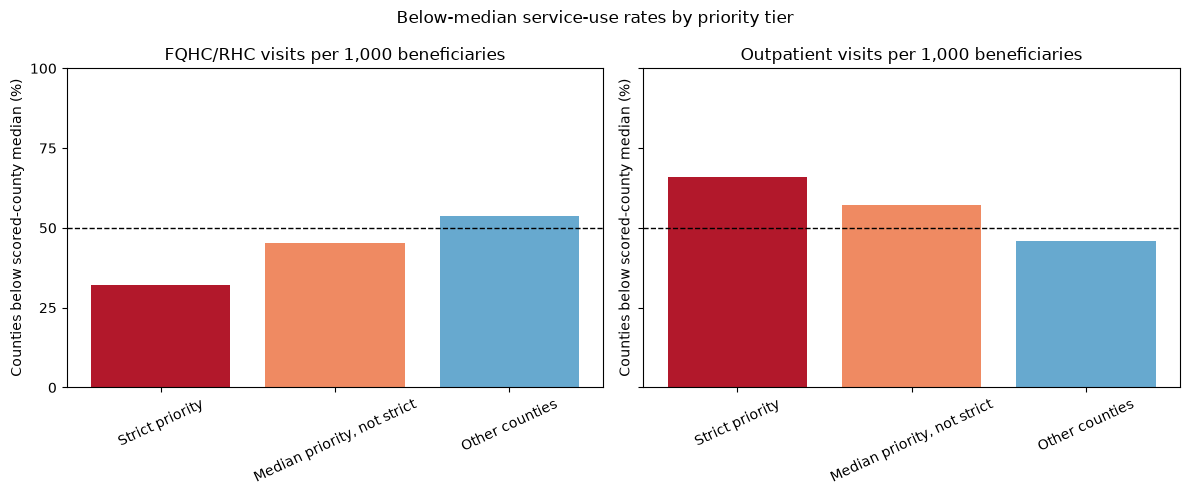

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (column, label) in zip(axes, service_use_labels.items()):
    plot_data = below_median_profile.loc[
        below_median_profile["Indicator"] == label
    ].set_index("Priority tier").reindex(priority_tier_order)
    ax.bar(
        priority_tier_order,
        plot_data["Below median (%)"],
        color=["#b2182b", "#ef8a62", "#67a9cf"],
    )
    ax.axhline(50, color="black", linestyle="--", linewidth=1)
    ax.set_title(label)
    ax.set_ylabel("Counties below scored-county median (%)")
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.tick_params(axis="x", labelrotation=25)
fig.suptitle("Below-median service-use rates by priority tier")
fig.tight_layout()
plt.show()

## Add a closer-to-2024 primary-care supply measure

The [HRSA AHRF 2024–2025 county file](https://data.hrsa.gov/DataDownload/AHRF/AHRF_2024-2025_CSV.zip) includes `phys_nf_prim_care_pc_exc_rsdt_23`: non-federal primary-care physicians in patient care, excluding hospital residents and physicians age 75 or older (AMA Physician Master File, 2023 count). The denominator, `popn_est_24`, is the 2024 Census county population estimate. This section calculates physicians per 100,000 residents, compares the follow-up shortlist with other scored counties, and maps the rate. The numerator is from 2023, so this is close to—but not an exact—2024 supply measure. Physician density is a supply proxy; it does not capture within-county distribution, appointment availability, or all primary-care clinicians.

Overall scored-county median: 44.49 primary-care physicians per 100,000 residents.


,County group,Count with data,"Median physicians per 100,000",25th percentile,75th percentile,Below overall median (%)
0,Follow-up shortlist,62,25.65,14.72,47.67,72.58
1,Other strict-priority counties,227,29.94,16.06,46.12,74.01
2,Other scored counties,2698,46.16,28.12,71.30,47.44


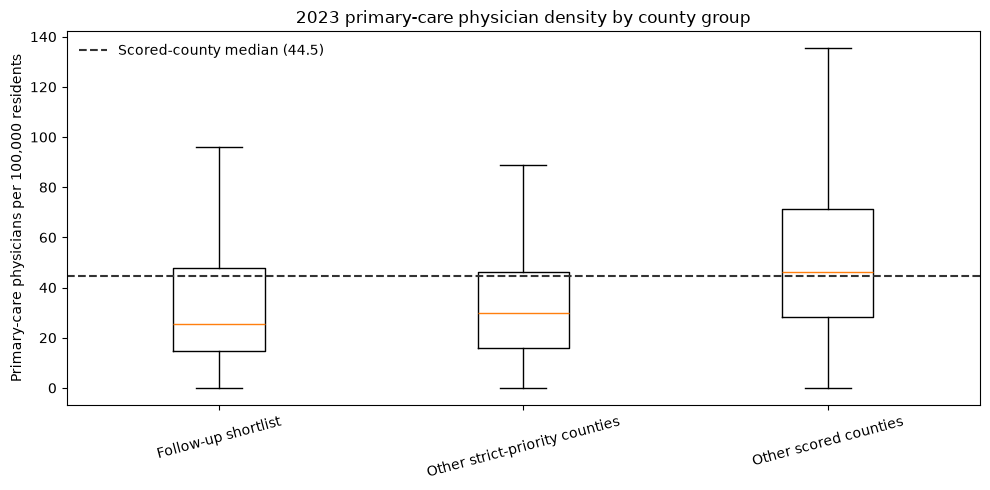

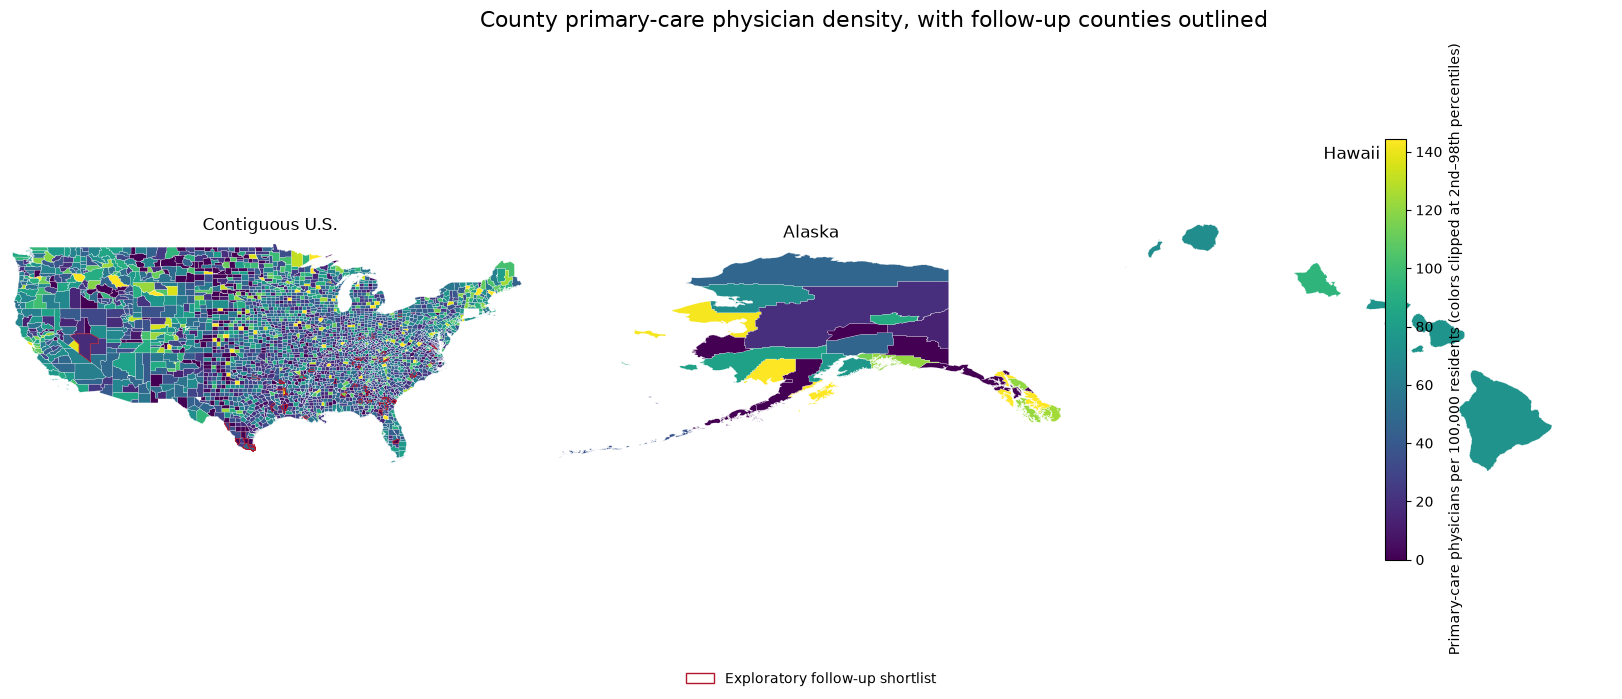

Scored counties with AHRF physician density: 2,987 of 2,996
Follow-up counties with AHRF physician density: 62 of 62


In [31]:
import ssl
import zipfile
from urllib.request import urlopen

import certifi
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Polygon as MapPolygon

ahrf_url = "https://data.hrsa.gov/DataDownload/AHRF/AHRF_2024-2025_CSV.zip"
ahrf_path = PROJECT_ROOT / "data/raw/ahrf_2024_2025_county_csv.zip"
ahrf_path.parent.mkdir(parents=True, exist_ok=True)
if not ahrf_path.exists():
    ahrf_context = ssl.create_default_context(cafile=certifi.where())
    with urlopen(ahrf_url, context=ahrf_context, timeout=120) as response:
        ahrf_path.write_bytes(response.read())

with zipfile.ZipFile(ahrf_path) as ahrf_archive:
    hp_member = next(
        name for name in ahrf_archive.namelist()
        if name.endswith("AHRF2025hp.csv")
    )
    pop_member = next(
        name for name in ahrf_archive.namelist()
        if name.endswith("AHRF2025pop.csv")
    )
    ahrf_physicians = pd.read_csv(
        ahrf_archive.open(hp_member),
        dtype={"fips_st_cnty": str},
        usecols=["fips_st_cnty", "phys_nf_prim_care_pc_exc_rsdt_23"],
    )
    ahrf_population = pd.read_csv(
        ahrf_archive.open(pop_member),
        dtype={"fips_st_cnty": str},
        usecols=["fips_st_cnty", "popn_est_24"],
    )

ahrf_county_supply = ahrf_physicians.merge(
    ahrf_population,
    on="fips_st_cnty",
    how="outer",
    validate="one_to_one",
).rename(columns={
    "fips_st_cnty": "CountyFIPS",
    "phys_nf_prim_care_pc_exc_rsdt_23": "PrimaryCarePhysicians2023",
    "popn_est_24": "PopulationEstimate2024",
})
ahrf_county_supply["CountyFIPS"] = ahrf_county_supply["CountyFIPS"].str.zfill(5)
for column in ["PrimaryCarePhysicians2023", "PopulationEstimate2024"]:
    ahrf_county_supply[column] = pd.to_numeric(
        ahrf_county_supply[column], errors="coerce"
    )
ahrf_county_supply["PrimaryCarePhysiciansPer100k"] = (
    ahrf_county_supply["PrimaryCarePhysicians2023"]
    / ahrf_county_supply["PopulationEstimate2024"].where(
        ahrf_county_supply["PopulationEstimate2024"].gt(0)
    )
    * 100_000
)

ahrf_scored = score_df.merge(
    ahrf_county_supply[["CountyFIPS", "PrimaryCarePhysiciansPer100k"]],
    on="CountyFIPS",
    how="left",
    validate="one_to_one",
)
supply_fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
supply_outpatient_column = "OP_VISITS_PER_1000_BENES"
supply_followup_mask = (
    ahrf_scored["StrictPriority"]
    & ahrf_scored[supply_fqhc_column].lt(ahrf_scored[supply_fqhc_column].median())
    & ahrf_scored[supply_outpatient_column].lt(ahrf_scored[supply_outpatient_column].median())
)
supply_group_masks = {
    "Follow-up shortlist": supply_followup_mask,
    "Other strict-priority counties": ahrf_scored["StrictPriority"] & ~supply_followup_mask,
    "Other scored counties": ~ahrf_scored["StrictPriority"],
}
overall_supply_median = ahrf_scored["PrimaryCarePhysiciansPer100k"].median()
supply_profile_rows = []
supply_boxplot_data = []
for label, mask in supply_group_masks.items():
    values = ahrf_scored.loc[mask, "PrimaryCarePhysiciansPer100k"].dropna()
    supply_boxplot_data.append(values)
    below_count = int(values.lt(overall_supply_median).sum())
    supply_profile_rows.append({
        "County group": label,
        "Count with data": len(values),
        "Median physicians per 100,000": values.median(),
        "25th percentile": values.quantile(0.25),
        "75th percentile": values.quantile(0.75),
        "Below overall median (%)": 100 * below_count / len(values) if len(values) else np.nan,
    })
supply_profile = pd.DataFrame(supply_profile_rows)
print(
    f"Overall scored-county median: {overall_supply_median:.2f} primary-care "
    "physicians per 100,000 residents."
)
display(supply_profile.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(
    supply_boxplot_data,
    tick_labels=list(supply_group_masks),
    showfliers=False,
)
ax.axhline(
    overall_supply_median,
    color="#333333",
    linestyle="--",
    label=f"Scored-county median ({overall_supply_median:.1f})",
)
ax.set_ylabel("Primary-care physicians per 100,000 residents")
ax.tick_params(axis="x", labelrotation=15)
ax.set_title("2023 primary-care physician density by county group")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

provider_by_fips = ahrf_county_supply.set_index("CountyFIPS")["PrimaryCarePhysiciansPer100k"]
provider_values = provider_by_fips.dropna()
map_lower, map_upper = provider_values.quantile([0.02, 0.98])
provider_norm = Normalize(vmin=map_lower, vmax=map_upper, clip=True)
supply_followup_fips = set(
    ahrf_scored.loc[supply_followup_mask, "CountyFIPS"]
)
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    patch_values = []
    edge_colors = []
    line_widths = []
    for vertices, county_fips in region_polygons[region]:
        value = provider_by_fips.get(county_fips)
        if pd.notna(value):
            patches.append(MapPolygon(vertices, closed=True))
            patch_values.append(value)
            is_followup = county_fips in supply_followup_fips
            edge_colors.append("#b2182b" if is_followup else "white")
            line_widths.append(0.55 if is_followup else 0.15)

    collection = PatchCollection(
        patches,
        cmap="viridis",
        norm=provider_norm,
        edgecolor=edge_colors,
        linewidth=line_widths,
    )
    collection.set_array(np.asarray(patch_values))
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

provider_colorbar = fig.colorbar(
    ScalarMappable(norm=provider_norm, cmap="viridis"),
    ax=axes.tolist(),
    shrink=0.78,
    pad=0.02,
)
provider_colorbar.set_label(
    "Primary-care physicians per 100,000 residents "
    "(colors clipped at 2nd–98th percentiles)"
)
fig.legend(
    handles=[Patch(facecolor="none", edgecolor="#b2182b", label="Exploratory follow-up shortlist")],
    loc="lower center",
    frameon=False,
)
fig.suptitle("County primary-care physician density, with follow-up counties outlined", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.91, bottom=0.10, top=0.88, wspace=0.04)
plt.show()

print(f"Scored counties with AHRF physician density: {ahrf_scored['PrimaryCarePhysiciansPer100k'].notna().sum():,} of {len(ahrf_scored):,}")
print(f"Follow-up counties with AHRF physician density: {ahrf_scored.loc[supply_followup_mask, 'PrimaryCarePhysiciansPer100k'].notna().sum():,} of {int(supply_followup_mask.sum())}")

## Triangulate provider-supply signals for follow-up

This comparison checks whether exploratory follow-up counties also have (1) below-median AHRF primary-care physician density and/or (2) a current county-linked HRSA geographic primary-care HPSA record. These are complementary but imperfect signals: the physician rate uses a 2023 count and 2024 population, while HPSA is a current snapshot. The table and chart are descriptive; they do not create a composite score or establish that a county lacks access. “Neither signal observed” means neither flag is present—not that access is adequate. An HPSA record may cover only part of a county.

,County group,Counties,With AHRF density,AHRF density unavailable,Below-median density + HPSA record (n),Below-median density + HPSA record (%),Below-median density only (n),Below-median density only (%),HPSA record only (n),HPSA record only (%),Neither signal observed (n),Neither signal observed (%)
0,Follow-up shortlist,62,62,0,23,37.1,22,35.5,3,4.8,14,22.6
1,Other strict-priority counties,227,227,0,66,29.1,102,44.9,10,4.4,49,21.6
2,Other scored counties,2707,2698,9,506,18.8,774,28.7,284,10.5,1134,42.0


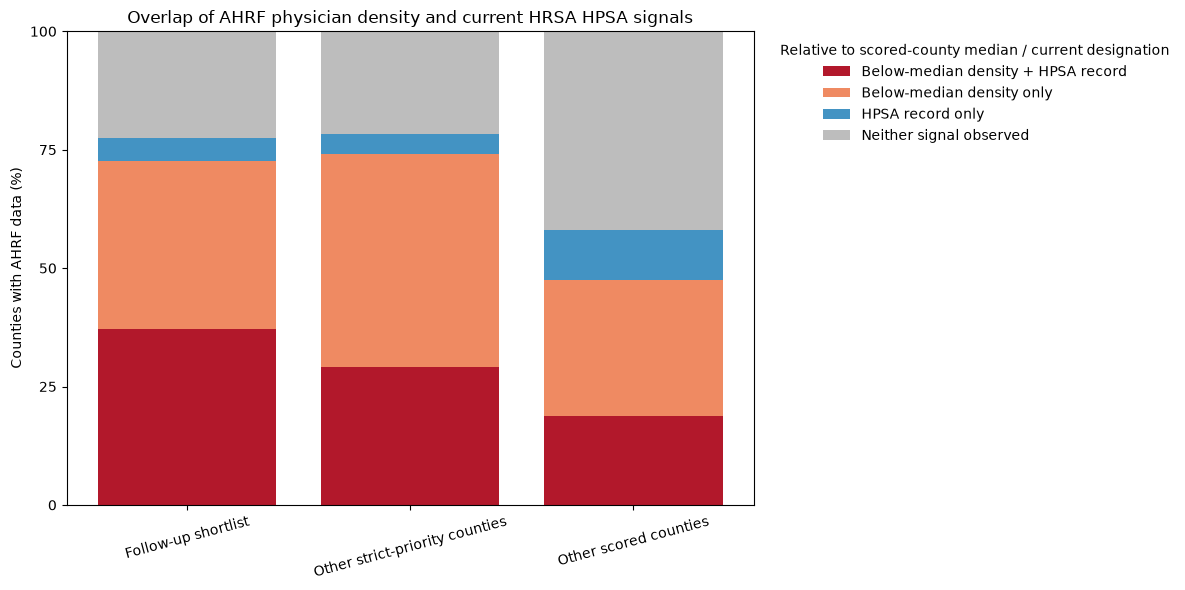

Follow-up shortlist counties with both contextual signals: 23 of 62.


,StateAbbr,CountyName,CountyFIPS,NeedScore,PrimaryCarePhysiciansPer100k,ActivePrimaryCareGeographicHPSARecords,FQHC_RHC_VISITS_PER_1000_BENES,OP_VISITS_PER_1000_BENES,BENES_TOTAL_CNT
363,GA,Atkinson,13003,5.36,0.00,1,713.24,4857.84,1566.0
2565,TX,Newton,48351,5.29,0.00,1,724.37,3747.15,3108.0
2341,TN,Fentress,47049,5.28,24.84,1,271.09,2666.45,6318.0
2636,TX,Zapata,48505,4.98,0.00,1,941.77,2473.90,2210.0
2697,VA,Emporia,51595,4.66,0.00,1,305.22,3341.37,1344.0
2360,TN,Jackson,47087,4.65,8.08,1,796.78,3371.56,3295.0
317,FL,Hamilton,12047,4.51,13.95,1,394.24,2473.84,3575.0
2517,TX,Jasper,48241,3.98,27.35,1,660.03,3644.30,9378.0
2469,TX,Duval,48131,3.95,0.00,1,735.20,2056.07,2514.0
2551,TX,Maverick,48323,3.89,25.50,1,970.97,2061.80,11609.0


In [32]:
triangulated_scored = ahrf_scored.merge(
    hpsa_scored[[
        "CountyFIPS", "HasActivePrimaryCareGeographicHPSA",
        "ActivePrimaryCareGeographicHPSARecords",
    ]],
    on="CountyFIPS",
    how="left",
    validate="one_to_one",
)
if triangulated_scored["HasActivePrimaryCareGeographicHPSA"].isna().any():
    raise ValueError("Some scored counties are missing the HRSA county-level HPSA flag.")

triangulated_scored["FollowUpCandidate"] = (
    triangulated_scored["StrictPriority"]
    & triangulated_scored[supply_fqhc_column].lt(
        score_df[supply_fqhc_column].median()
    )
    & triangulated_scored[supply_outpatient_column].lt(
        score_df[supply_outpatient_column].median()
    )
)
triangulated_scored["BelowMedianPhysicianDensity"] = (
    triangulated_scored["PrimaryCarePhysiciansPer100k"].lt(overall_supply_median)
)
triangulation_patterns = [
    "Below-median density + HPSA record",
    "Below-median density only",
    "HPSA record only",
    "Neither signal observed",
]
has_density = triangulated_scored["PrimaryCarePhysiciansPer100k"].notna()
low_density = triangulated_scored["BelowMedianPhysicianDensity"]
has_hpsa = triangulated_scored["HasActivePrimaryCareGeographicHPSA"]
triangulated_scored["ProviderSignalPattern"] = np.select(
    [
        has_density & low_density & has_hpsa,
        has_density & low_density & ~has_hpsa,
        has_density & ~low_density & has_hpsa,
        has_density & ~low_density & ~has_hpsa,
    ],
    triangulation_patterns,
    default="AHRF density unavailable",
)
triangulation_group_masks = {
    "Follow-up shortlist": triangulated_scored["FollowUpCandidate"],
    "Other strict-priority counties": (
        triangulated_scored["StrictPriority"]
        & ~triangulated_scored["FollowUpCandidate"]
    ),
    "Other scored counties": ~triangulated_scored["StrictPriority"],
}

triangulation_rows = []
for group_label, group_mask in triangulation_group_masks.items():
    group = triangulated_scored.loc[group_mask]
    valid_group = group.loc[group["PrimaryCarePhysiciansPer100k"].notna()]
    row = {
        "County group": group_label,
        "Counties": len(group),
        "With AHRF density": len(valid_group),
        "AHRF density unavailable": len(group) - len(valid_group),
    }
    for pattern in triangulation_patterns:
        count = int(valid_group["ProviderSignalPattern"].eq(pattern).sum())
        row[f"{pattern} (n)"] = count
        row[f"{pattern} (%)"] = (
            100 * count / len(valid_group) if len(valid_group) else np.nan
        )
    triangulation_rows.append(row)
triangulation_profile = pd.DataFrame(triangulation_rows)
display(triangulation_profile.round(1))

pattern_colors = ["#b2182b", "#ef8a62", "#4393c3", "#bdbdbd"]
fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(triangulation_profile))
for pattern, color in zip(triangulation_patterns, pattern_colors):
    shares = triangulation_profile[f"{pattern} (%)"].fillna(0).to_numpy()
    ax.bar(
        triangulation_profile["County group"],
        shares,
        bottom=bottom,
        color=color,
        label=pattern,
    )
    bottom += shares
ax.set_ylabel("Counties with AHRF data (%)")
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100])
ax.tick_params(axis="x", labelrotation=15)
ax.set_title("Overlap of AHRF physician density and current HRSA HPSA signals")
ax.legend(title="Relative to scored-county median / current designation", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

both_signal_followup = triangulated_scored.loc[
    triangulated_scored["FollowUpCandidate"]
    & triangulated_scored["ProviderSignalPattern"].eq(
        "Below-median density + HPSA record"
    )
].sort_values("NeedScore", ascending=False)
print(
    f"Follow-up shortlist counties with both contextual signals: "
    f"{len(both_signal_followup)} of {int(triangulated_scored['FollowUpCandidate'].sum())}."
)
display(both_signal_followup[
    [
        "StateAbbr", "CountyName", "CountyFIPS", "NeedScore",
        "PrimaryCarePhysiciansPer100k", "ActivePrimaryCareGeographicHPSARecords",
        supply_fqhc_column, supply_outpatient_column, "BENES_TOTAL_CNT",
    ]
].round(2))

## Check sensitivity to the physician-density cutoff

The earlier overlap used the scored-county median to flag low AHRF physician density. Because that cutoff is a choice, this check repeats the comparison at the 25th, 50th, and 75th percentiles of scored-county density. For each county group, it reports how many fall below each cutoff and how many also have a current geographic primary-care HPSA record. Percentiles use counties with observed AHRF density; ties can make the share below a cutoff differ from the nominal percentile. This is a robustness check, not a new county designation.

,Density cutoff,"Cutoff (physicians per 100,000)",County group,Count with density,Below cutoff (n),Below cutoff (%),Below cutoff + HPSA (n),With both signals (% of group),HPSA among below cutoff (%)
0,25th percentile,26.40,Follow-up shortlist,62,32,51.61,20,32.26,62.50
1,25th percentile,26.40,Other strict-priority counties,227,100,44.05,53,23.35,53.00
2,25th percentile,26.40,Other scored counties,2698,615,22.79,303,11.23,49.27
3,50th percentile (median),44.49,Follow-up shortlist,62,45,72.58,23,37.10,51.11
4,50th percentile (median),44.49,Other strict-priority counties,227,168,74.01,66,29.07,39.29
5,50th percentile (median),44.49,Other scored counties,2698,1280,47.44,506,18.75,39.53
6,75th percentile,69.01,Follow-up shortlist,62,55,88.71,24,38.71,43.64
7,75th percentile,69.01,Other strict-priority counties,227,207,91.19,74,32.60,35.75
8,75th percentile,69.01,Other scored counties,2698,1978,73.31,663,24.57,33.52


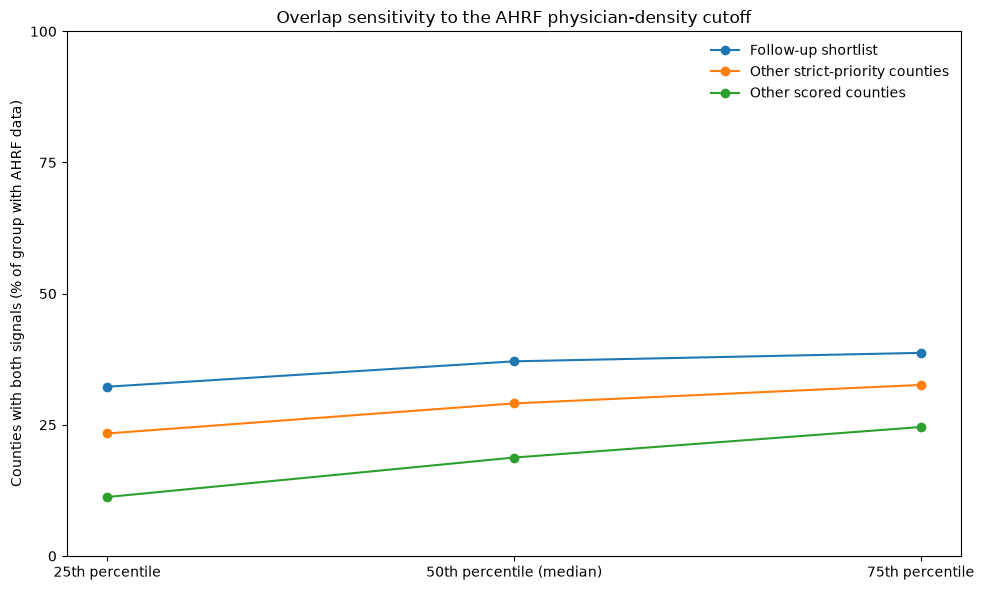

In [33]:
density_quantiles = ahrf_scored["PrimaryCarePhysiciansPer100k"].dropna().quantile(
    [0.25, 0.50, 0.75]
)
density_thresholds = [
    ("25th percentile", float(density_quantiles.loc[0.25])),
    ("50th percentile (median)", float(density_quantiles.loc[0.50])),
    ("75th percentile", float(density_quantiles.loc[0.75])),
]
density_sensitivity_rows = []
for threshold_label, threshold_value in density_thresholds:
    for group_label, group_mask in triangulation_group_masks.items():
        group = triangulated_scored.loc[group_mask]
        valid_group = group.loc[group["PrimaryCarePhysiciansPer100k"].notna()]
        below_cutoff = valid_group["PrimaryCarePhysiciansPer100k"].lt(threshold_value)
        below_and_hpsa = (
            below_cutoff
            & valid_group["HasActivePrimaryCareGeographicHPSA"]
        )
        below_count = int(below_cutoff.sum())
        both_count = int(below_and_hpsa.sum())
        density_sensitivity_rows.append({
            "Density cutoff": threshold_label,
            "Cutoff (physicians per 100,000)": threshold_value,
            "County group": group_label,
            "Count with density": len(valid_group),
            "Below cutoff (n)": below_count,
            "Below cutoff (%)": 100 * below_count / len(valid_group),
            "Below cutoff + HPSA (n)": both_count,
            "With both signals (% of group)": 100 * both_count / len(valid_group),
            "HPSA among below cutoff (%)": (
                100 * both_count / below_count if below_count else np.nan
            ),
        })
density_sensitivity_profile = pd.DataFrame(density_sensitivity_rows)
display(density_sensitivity_profile.round(2))

fig, ax = plt.subplots(figsize=(10, 6))
threshold_labels = [label for label, _ in density_thresholds]
for group_label in triangulation_group_masks:
    group_profile = (
        density_sensitivity_profile.loc[
            density_sensitivity_profile["County group"].eq(group_label)
        ]
        .set_index("Density cutoff")
        .reindex(threshold_labels)
    )
    ax.plot(
        threshold_labels,
        group_profile["With both signals (% of group)"],
        marker="o",
        label=group_label,
    )
ax.set_ylabel("Counties with both signals (% of group with AHRF data)")
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_title("Overlap sensitivity to the AHRF physician-density cutoff")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [34]:
score_df.to_csv(
    PROJECT_ROOT / "data/processed/county_need_readmission_quadrants_2024.csv",
    index=False,
)